# **Project 2: Deep generative models for personalised oncology** · ML for Healthcare, UC3M 2026/27



## 1. Load the Data

In [4]:
import importlib.util
import pandas as pd
from packaging.version import Version
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.io
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
import scvi
import torch

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

import urllib.request
import json
import shutil
import ssl


warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.set_figure_params(dpi=90, frameon=False)

SEED = 0
scvi.settings.seed = SEED
rng = np.random.default_rng(SEED)

c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Seed set to 0


In [2]:
print("pandas", pd.__version__, "| scvi-tools", scvi.__version__, "| scanpy", sc.__version__, "| GPU:", torch.cuda.is_available())

pandas 3.1.0 | scvi-tools 1.5.2 | scanpy 1.12.5 | GPU: False


In [5]:
DATA_DIR = Path("../../data")
H5AD_PATH = DATA_DIR / "wu_2021_breast_cancer.h5ad"
GEO_DIR = DATA_DIR / "geo_data"  # Backup source if CELLxGENE fails

CXG_COLLECTION_ID = "dea97145-f712-431c-a223-6b5f565f362a"
CXG_DATASET_ID    = "9fddb063-056d-4202-8b8a-4b0ee531d3ce"

# Set to None to keep the full dataset for EDA (skips subsampling)
N_CELLS = None 
SEED = 42

#  Helper Functions 
def to_dense(x):
    if sp.issparse(x):
        return x.toarray()
    if hasattr(x, "todense"):
        return np.asarray(x.todense())
    return np.asarray(x)

# We need raw counts as input to scVI and for scanpy functions
def is_integer_counts(X, n=500):
    sub = to_dense(X[:n])
    return bool(np.all(sub >= 0) and np.allclose(sub, np.round(sub)))

def ssl_context():
    try:
        import certifi
        return ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        return ssl.create_default_context()

In [ ]:
def download_from_cellxgene():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    api_url = (f"https://api.cellxgene.cziscience.com/curation/v1/collections/"
               f"{CXG_COLLECTION_ID}/datasets/{CXG_DATASET_ID}")
    ctx = ssl_context()
    with urllib.request.urlopen(api_url, context=ctx) as r:
        meta = json.load(r)
    url = next((a["url"] for a in meta.get("assets", []) if a.get("filetype") == "H5AD"), None)
    if url is None:
        raise ValueError("No H5AD file found in the CELLxGENE dataset metadata.")

    print(f"Downloading {url} (~850 MB), this can take a while...")
    tmp_path = H5AD_PATH.with_suffix(".h5ad.part")
    with urllib.request.urlopen(url, context=ctx) as r, open(tmp_path, "wb") as f:
        shutil.copyfileobj(r, f, length=16 * 1024 * 1024)
    tmp_path.rename(H5AD_PATH)
    print("Download complete.")

In [ ]:
def load_wu2021():
    if not H5AD_PATH.exists() and not GEO_DIR.exists():
        print("Data not found locally, downloading it from CELLxGENE.")
        try:
            download_from_cellxgene()
        except Exception as e:
            raise FileNotFoundError(f"Automatic download failed ({e}). Download manually to {H5AD_PATH}.") from e

    if H5AD_PATH.exists():
        adata = sc.read_h5ad(H5AD_PATH)
        if not is_integer_counts(adata.X):
            assert adata.raw is not None, "X is not raw counts and there is no .raw"
            adata = adata.raw.to_adata()
        
        if "feature_name" in adata.var: # CELLxGENE uses Ensembl IDs as the index
            adata.var["ensembl_id"] = adata.var_names
            adata.var_names = adata.var["feature_name"].astype(str)
            
    elif GEO_DIR.exists():
        X = sp.mmread(GEO_DIR / "count_matrix_sparse.mtx").tocsr()
        genes = pd.read_csv(GEO_DIR / "count_matrix_genes.tsv", header=None, sep="\t")[0].astype(str).values
        barcodes = pd.read_csv(GEO_DIR / "count_matrix_barcodes.tsv", header=None, sep="\t")[0].astype(str).values
        if X.shape[0] == len(genes) and X.shape[1] == len(barcodes):
            X = X.T.tocsr()
        meta = pd.read_csv(GEO_DIR / "metadata.csv", index_col=0)
        adata = ad.AnnData(X=X, obs=meta.loc[barcodes].copy(), var=pd.DataFrame(index=genes))
    else:
        raise FileNotFoundError("Data file not found.")

    adata.var_names_make_unique()
    assert is_integer_counts(adata.X), "The matrix doesn't look like raw counts"
    return adata

def first_col(obs, candidates):
    for c in candidates:
        if c in obs.columns:
            return c
    raise KeyError(f"None of {candidates} found in obs: {list(obs.columns)}")

# processing
adata = load_wu2021()

# Standardizing names 
COLMAP = {
    "patient":        first_col(adata.obs, ["orig.ident", "donor_id", "Patient", "patient"]),
    "subtype":        first_col(adata.obs, ["subtype", "Subtype", "clinical_subtype", "disease"]),
    "celltype":       first_col(adata.obs, ["celltype_major", "author_cell_type", "cell_type"]),
    "celltype_minor": first_col(adata.obs, ["celltype_minor", "celltype_major", "author_cell_type", "cell_type"]),
}

for std, orig in COLMAP.items():
    adata.obs[std] = adata.obs[orig].astype(str).astype("category")

Loaded: 100,064 cells × 28,523 genes | 26 patients


In [ ]:
# ---------------- GLOBAL CONFIG ----------------
DATA_DIR    = Path("data")
H5AD_PATH   = DATA_DIR / "wu2021_brca.h5ad"                # option A: .h5ad from CELLxGENE
GEO_DIR     = DATA_DIR / "Wu_etal_2021_BRCA_scRNASeq"      # option B: extracted GEO GSE176078 folder
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR  = Path("models");  MODELS_DIR.mkdir(exist_ok=True)

Voy a meter todo el dataset en el modelo y a partir de ahí iremos sacando conclusiones.

In [ ]:
# DO NOT RUN
if N_CELLS is not None and adata.n_obs > N_CELLS:
    sc.pp.subsample(adata, n_obs=N_CELLS, random_state=SEED)

print(f"Loaded: {adata.n_obs:,} cells × {adata.n_vars:,} genes | {adata.obs['patient'].nunique()} patients")

# IR DIRECTAMENTE A HIPÓTESIS 6

## 2. Preprocess

In [ ]:
# DO NOT RUN
N_CELLS      = 30_000   # None = full atlas (~100k). Smaller.
N_HVG        = 2_000

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=10)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

try:
    sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3",
                                layer="counts", batch_key="patient", subset=True)
except Exception as e:  # patients with very few cells can make the loess fit fail
    print("Per-patient HVG selection failed, using global HVGs instead:", e)
    sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3", layer="counts", subset=True)
adata

## 3. Model

In [6]:
N_CELLS      = None  # None = full atlas (~100k). Smaller.
N_LATENT     = 10       # same as the paper; PCA uses the same dimension so the comparison is fair
MAX_EPOCHS   = None     # None = scvi-tools default heuristic
K_NEIGHBORS  = 50       # neighbourhood size for the mixing entropy (as in the paper)
RETRAIN      = False    # True = retrain even if saved models already exist

In [ ]:
a = adata.copy()
n_latent = N_LATENT
gene_likelihood = "nb"
path = MODELS_DIR / "full_nb"

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Epoch 80/80: 100%|██████████| 80/80 [23:15:39<00:00, 147.01s/it, v_num=1, train_loss=5.18e+3]      

`Trainer.fit` stopped: `max_epochs=80` reached.


Epoch 80/80: 100%|██████████| 80/80 [23:15:39<00:00, 1046.74s/it, v_num=1, train_loss=5.18e+3]


In [ ]:
scvi.model.SCVI.setup_anndata(a, batch_key=None)

model = scvi.model.SCVI(a, n_latent=n_latent, gene_likelihood=gene_likelihood)
model.train(max_epochs=MAX_EPOCHS, early_stopping=True, check_val_every_n_epoch=1)
model.save(path, overwrite=True)

In [ ]:
model = scvi.model.SCVI.load(path, adata=a)

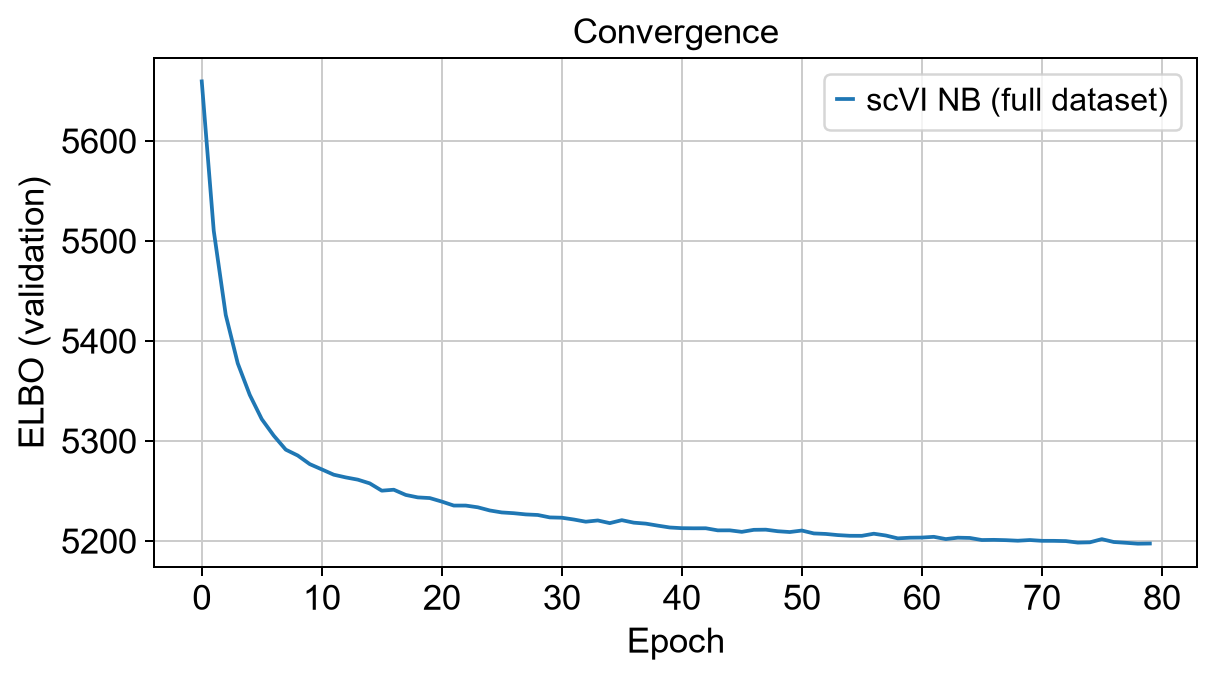

In [9]:
# Training curves: validation ELBO
# Check convergence and potential overfitting

fig, ax = plt.subplots(figsize=(7, 4))

h = model.history

if "elbo_validation" in h:
    ax.plot(
        h["elbo_validation"].values.ravel(),
        label="scVI NB (full dataset)"
    )
else:
    print("Validation ELBO not available")

ax.set(
    xlabel="Epoch",
    ylabel="ELBO (validation)",
    title="Convergence"
)

ax.legend()
plt.tight_layout()
plt.show()

## 3. Testings

UMAP

In [10]:
adata.obsm["X_scvi_nb"] = model.get_latent_representation(a)

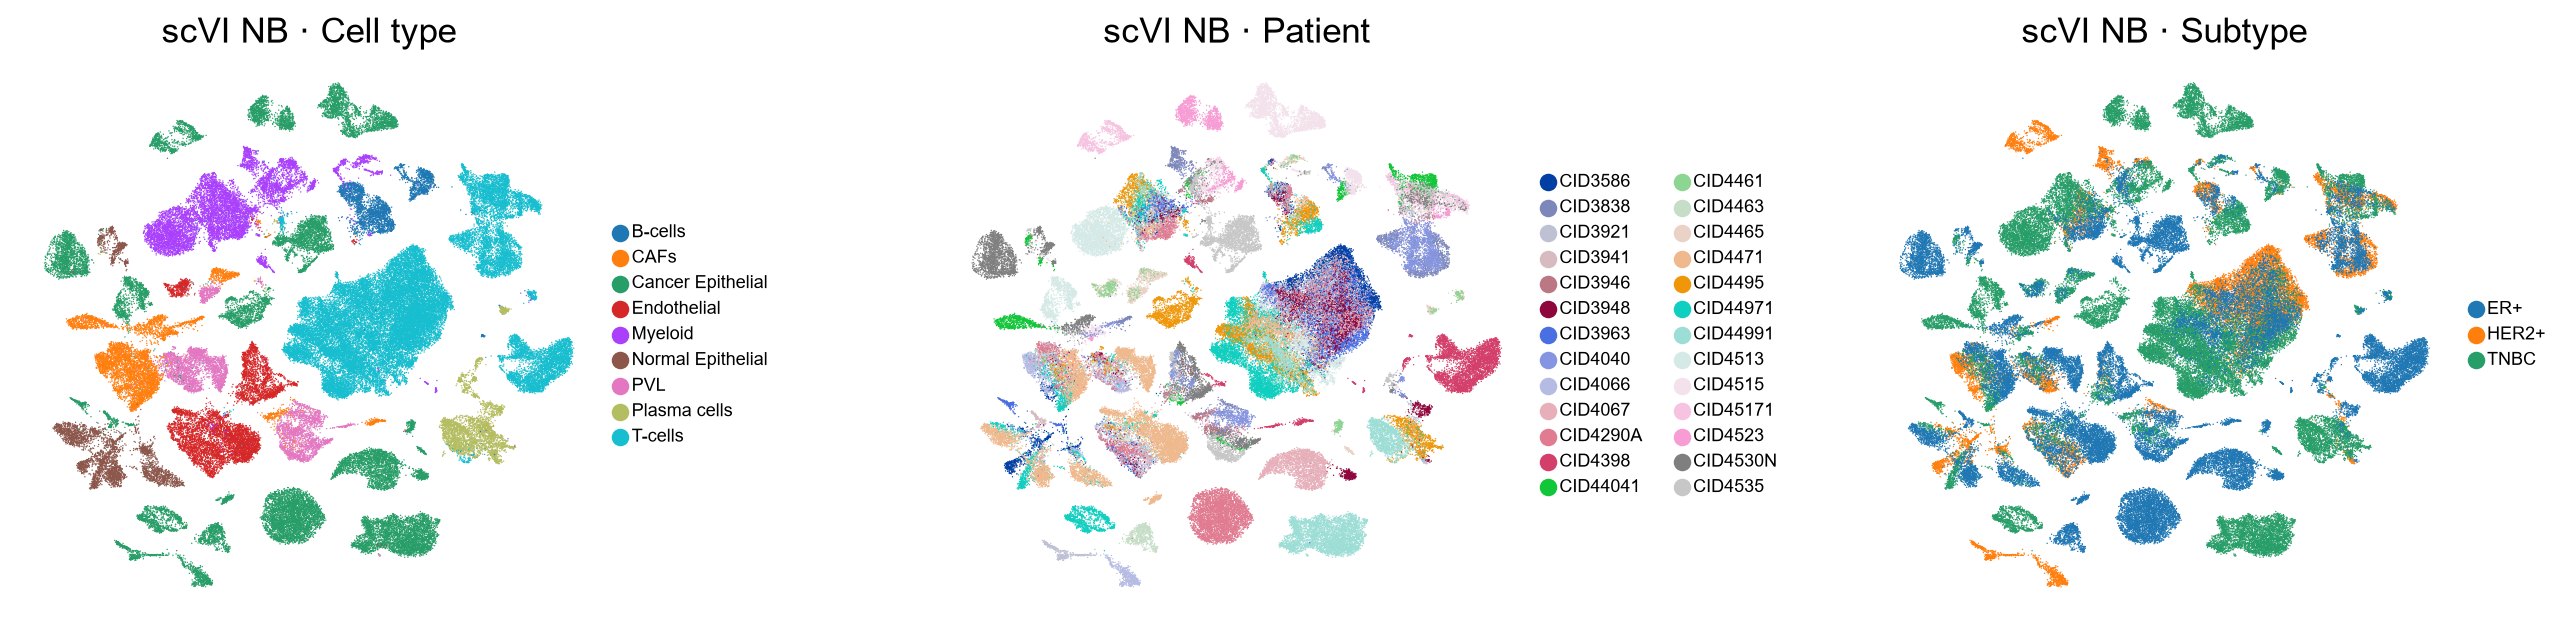

In [11]:
# Neighbour graph
sc.pp.neighbors(
    adata,
    use_rep="X_scvi_nb",
    random_state=SEED
)

# UMAP
sc.tl.umap(
    adata,
    random_state=SEED
)

# Save UMAP coordinates
adata.obsm["X_umap_scvi_nb"] = adata.obsm["X_umap"].copy()

# Plot
sc.pl.embedding(
    adata,
    basis="X_umap_scvi_nb",
    color=["celltype", "patient", "subtype"],
    wspace=0.45,
    legend_fontsize=7,
    title=[
        "scVI NB · Cell type",
        "scVI NB · Patient",
        "scVI NB · Subtype"
    ]
)

Vemos que cada célula se comporta de manera diferente unas de otras, 

1) Cancer epithelial pueden ser útil para detectar a qué paciente pertenecen.

2) Como vemos, los grupos que antes eran verdes haciendo referencia a Cancer epithelial, ahora tienen un solo color, donde cada color hace referencia a cada paciente, es decir, estábamos en lo correcto.

En conclusión, podemos determinar que ciertos comportamientos hacen referencia a diferentes pacientes, células, y tipos de cáncer.

Aunque esto no es suficiente para demostrar nada, vamos a centrarnos en nuestra pregunta para ir investigando cada vez más y acercarnos a nuestro objetivo.

**PREGUNTA A)** ¿Debemos considerar a cada paciente como un lote (batch) y eliminar las diferencias entre ellos durante la integración?
Esto quiere decir que cualquier diferencia entre pacientes se debe a que son diferentes pacientes y no diferencia biológica.

Como ya sabemos anteriormente cada célula cancerígena es específica para cada paciente, pero para las T-cells por ejemplo, esas diferencias entre ellas (que a priori no somos capaces de visualizar en un UMAP) se deben al paciente o realmente tienen una carga genética.

Otros tipos de células con comportamineto similar entre pacientes son (Myeloid, CAFs)

¿Cómo podemos saber si diferenciar es realemnte útil o no?


**Hipótesis 1:** ¿Podemos identificar a "X" paciente mediante sus T-cells?
Para responder esta pregunta planteamos un clasificador, pero, debemos tener cuidado a la hora de entrenarlo ya que podría estar aprendiendo diferencias no solo biológicas sino técnicas.

Si el clasificador identifica al paciente podriamos concluir que existen diferencias biológicas entre las T-cells de los pacientes, por lo tanto, estaría justificado la separación por paciente (batch effect).

## Hipótesis 1:

In [ ]:
# Clasificador de paciente en células T: antes vs después de integrar (scVI)

# Pregunta: ¿se puede identificar al paciente a partir de sus células T?
#   - Antes de integrar (PCA sobre expresión log-normalizada)
#   - Después de integrar (espacio latente de scVI)

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import fisher_exact

In [14]:
PATIENT_KEY = "donor_id"        # columna del paciente en adata.obs
CELLTYPE_KEY = "cell_type"      # columna con el tipo celular
T_LABELS = ["T cell"]           # COMPRUEBA: adata.obs[CELLTYPE_KEY].unique()
LATENT_KEY = "X_scvi_nb"        # adata.obsm["X_scvi_nb"] = model.get_latent_representation(a)
COUNTS_LAYER = "counts"
SYMBOL_COL = "feature_name"     # CELLxGENE: var_names suelen ser Ensembl; los símbolos van aquí
N_LATENT = 10                   # = n_latent de tu scVI (el PCA usará el mismo nº de dimensiones)

MIN_PER_PATIENT = 50            # pacientes con menos células T se descartan
MAX_PER_PATIENT = 300           # submuestreo para equilibrar clases

N_HVG = 2000
N_FOLDS = 5
SEED = 0
rng = np.random.default_rng(SEED)

In [8]:
print(adata.obs["donor_id"].nunique(), adata.obs["patient"].nunique(),
      (adata.obs["donor_id"].astype(str) == adata.obs["patient"].astype(str)).all())

26 26 True


In [ ]:
batch_table = pd.crosstab(
    adata.obs["donor_id"],
    adata.obs["batch_run"]
)

display(batch_table)

batch_run,1,10,11,12,13,14,15,16,2,3,4,5,6,7,8,9
donor_id,,,,,,,,,,,,,,,,
CID3586,0,0,0,0,6178,0,0,0,0,0,0,0,0,0,0,0
CID3838,0,0,0,0,0,0,0,2353,0,0,0,0,0,0,0,0
CID3921,0,0,0,3024,0,0,0,0,0,0,0,0,0,0,0,0
CID3941,0,0,0,0,631,0,0,0,0,0,0,0,0,0,0,0
CID3946,0,0,0,0,0,0,0,774,0,0,0,0,0,0,0,0
CID3948,0,0,0,0,2327,0,0,0,0,0,0,0,0,0,0,0
CID3963,0,0,0,3527,0,0,0,0,0,0,0,0,0,0,0,0
CID4040,0,0,0,0,0,0,0,2531,0,0,0,0,0,0,0,0
CID4066,0,0,0,5309,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# %% 1. Subconjunto de células T, equilibrado por paciente
print(adata.obs["cell_type"].value_counts().head(15))   # verifica T_LABELS

# Seleccionar T-cells
adata_t = adata[
    (adata.obs["cell_type"] == "T-cells") &
    (adata.obs["patient"].notna())
].copy()

# Contar células por paciente
counts = adata_t.obs["patient"].value_counts()

# Mínimo inicial de 100 células
valid_donors = counts[counts >= 100].index

adata_t = adata_t[
    adata_t.obs["patient"].isin(valid_donors)
].copy()

print(f"Pacientes con >= {100} células T: {len(valid_donors)} de {adata.obs['patient'].nunique()}")
# 7 pacientes entre el umbral


# 3. Equilibrar pacientes: máximo 500 células por paciente
rng = np.random.default_rng(42)

selected_indices = []

for donor in valid_donors:
    donor_indices = np.where(
        adata_t.obs["patient"].values == donor
    )[0]

    n = min(len(donor_indices), 500)

    selected_indices.extend(
        rng.choice(donor_indices, n, replace=False)
    )

adata_t = adata_t[selected_indices].copy()


# Símbolos de gen (para MT-, RPS..., etc.)
# ¿Para qué sirve esto? Para poder identificar los genes por su símbolo en lugar de por su ID de Ensembl.
# ¿Qué es el simbolo de gen? Es un nombre corto y legible para un gen, como "TP53" o "BRCA1", que se utiliza en lugar del identificador de Ensembl, que es más largo y menos intuitivo.

if "feature_name" in adata_t.var.columns:
    symbols = adata_t.var["feature_name"].astype(str).values
else:
    symbols = adata_t.var_names.astype(str).values
adata_t.var["symbol"] = symbols

# 4. Extraer expresión génica y etiquetas
X = adata_t.X

X.head()

cell_type
CD4-positive, alpha-beta T cell             19231
luminal epithelial cell of mammary gland    14367
mammary gland epithelial cell               13379
CD8-positive, alpha-beta T cell             11487
endothelial cell                             7402
fibroblast of breast                         6573
macrophage                                   5929
pericyte                                     5423
plasma cell                                  3524
memory B cell                                2581
monocyte                                     2328
natural killer cell                          1846
T cell                                       1528
myeloid cell                                 1418
mature NK T cell                             1122
Name: count, dtype: int64
Pacientes con >= 50 células T: 7 de 26
1107 células T, 7 pacientes, nivel de azar = 0.143


Coger a 7 pacientes que tengan entre 50 y 300 T-cells
¿Qué siginifica nivel de azar?

### Preprocessing:

In [ ]:
# %% 2. Preprocessing. ANTES de integrar: normalizar -> HVG -> escalar

sc.pp.normalize_total(X, target_sum=1e4)
sc.pp.log1p(X)
sc.pp.highly_variable_genes(X, n_top_genes=2000, flavor="seurat")   # sin batch_key a propósito
X_hvg = X[:, X.var["highly_variable"]].copy()
sc.pp.scale(X_hvg, max_value=10)

sc.pp.pca(at_hvg, n_comps=10, random_state=0) 

X_pca = at_hvg.obsm["X_pca"]

X = X_hvg
y = X_hvg.obs["patient"].values

X_scvi = at.obsm["X_scvi_nb"] # anteriormente calculado con scVI adata.obsm["X_scvi_nb"] = model.get_latent_representation(a)
y_scvi = at.obs["patient"].values

In [ ]:
# 3. Dividir entrenamiento y test
# Hay que dividir por muestra, es decir manualmente, para que no haya células de la misma muestra en train y test sesgando el modelo.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Model:

In [ ]:
# 4. Construir el clasificador
model = Pipeline([
    ("gene_selection", SelectKBest(
        score_func=f_classif,
        k=min(2000, X.shape[1])
    )),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="saga",
        random_state=42
    ))
])


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


print("Accuracy:", accuracy_score(y_test, y_pred))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

In [ ]:
# 4.1. Construir Random Forest (también tiene feature importance)

In [ ]:
# %% 5. Controles y comparación
# Control técnico: solo métricas de QC (sin biología)

at.var["mt"] = pd.Series(symbols, index=at.var_names).str.upper().str.startswith("MT-").values

sc.pp.calculate_qc_metrics(at, qc_vars=["mt"], inplace=True, layer="counts_backup")

X_qc = at.obs[["log1p_total_counts", "log1p_n_genes_by_counts", "pct_counts_mt"]].values

results = pd.DataFrame([
    eval_rep(X_qc, y, "Solo QC (técnico)"),
    eval_rep(X_pca, y, f"PCA ({N_LATENT}) antes de integrar"),
    eval_rep(X_scvi, y, f"scVI ({X_scvi.shape[1]}) después de integrar"),
]).set_index("representation")
print(results.round(3))

# Gráfico
fig, ax = plt.subplots(figsize=(7, 4))
results[["logreg", "knn15"]].plot.bar(ax=ax)
ax.axhline(chance, color="k", ls="--", label=f"azar (1/{n_classes})")
ax.set_ylabel("Balanced accuracy (identificar paciente)")
ax.set_title("¿Se identifica al paciente con sus células T?")
ax.legend()
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# %% 6. Nivel de gen (ANTES de integrar): ¿qué genes distinguen a los pacientes?

# Regresión logística multinomial sobre HVG escalados; importancia = media del |coef| entre pacientes
Xg = at_hvg.X if isinstance(at_hvg.X, np.ndarray) else at_hvg.X.toarray()
gene_syms = at_hvg.var["symbol"].values
clf_g = LogisticRegression(max_iter=3000, C=0.05)   # C bajo = regularización fuerte, coeficientes más estables
clf_g.fit(Xg, y)
importance = pd.Series(np.abs(clf_g.coef_).mean(axis=0), index=gene_syms)
importance = importance.groupby(level=0).max().sort_values(ascending=False)

# Categorías (símbolos humanos). Lo que cae en "other" hay que revisarlo a mano.
CATEGORIES = {
    "technical: mitochondrial":     r"^MT-",
    "technical: ribosomal":         r"^RP[SL]\d",
    "technical: dissociation/stress": r"^(FOS|FOSB|JUN|JUNB|JUND|ATF3|EGR1|IER2|IER3|HSPA1A|HSPA1B|HSP90AA1|HSPB1|DNAJB1|DUSP1)$",
    "technical: ambient/contam.":   r"^(HBA1|HBA2|HBB|IGK[CV]|IGH[ACGMV]|IGL[CV]|MALAT1|NEAT1)",
    "biological: sex genes":        r"^(XIST|TSIX|RPS4Y1|DDX3Y|UTY|KDM5D|EIF1AY|ZFY)$",
    "biological: HLA/genotype":     r"^HLA-",
}
def categorize(g):
    for cat, pat in CATEGORIES.items():
        if pd.Series([g]).str.contains(pat, regex=True, case=False).iloc[0]:
            return cat
    return "other (inspeccionar)"

TOP_N = 100
top = importance.head(TOP_N)
cat_top = pd.Series({g: categorize(g) for g in top.index})
cat_all = pd.Series({g: categorize(g) for g in importance.index})

summary = pd.DataFrame({
    f"top{TOP_N} genes": cat_top.value_counts(),
    "todos los HVG": cat_all.value_counts(),
}).fillna(0).astype(int)
summary["% top"] = (100 * summary[f"top{TOP_N} genes"] / TOP_N).round(1)
summary["% fondo"] = (100 * summary["todos los HVG"] / len(importance)).round(1)

# Enriquecimiento de cada categoría en el top (Fisher, one-sided)
enr = []
for cat in summary.index:
    a = (cat_top == cat).sum(); b = TOP_N - a
    c = (cat_all == cat).sum() - a; d = len(importance) - TOP_N - c
    enr.append(fisher_exact([[a, b], [c, d]], alternative="greater")[1])
summary["p (enriquecimiento)"] = np.round(enr, 4)
print(summary)
print("\nTop 30 genes que distinguen pacientes (antes de integrar):")
print(top.head(30).round(3))

# Genes específicos por paciente (para ver si apuntan a biología tumoral/subtipo)
coef_df = pd.DataFrame(clf_g.coef_.T, index=gene_syms, columns=clf_g.classes_)
top_per_patient = {p: coef_df[p].nlargest(10).index.tolist() for p in coef_df.columns}
print(pd.DataFrame(top_per_patient).T)

In [ ]:
# %% 7. (Opcional) Nivel de gen DESPUÉS de integrar con scVI
# Expresión "libre de batch": se promedia sobre todos los pacientes como batch de destino,
# de modo que lo que queda diferente entre células viene de z y no de s (paciente).
# Requiere el objeto `model` (scVI entrenado) y que `at` conserve los mismos índices que `adata`.
def residual_gene_analysis(model, at, hvg_ids, y):
    batches = list(model.adata.obs[PATIENT_KEY].astype(str).unique())  # ajusta si tu categoría original no es str
    expr = model.get_normalized_expression(
        adata=model.adata[at.obs_names],
        gene_list=list(hvg_ids),
        transform_batch=batches,        # promedia sobre batches
        library_size=1e4,
        return_numpy=True,
    )
    expr = np.log1p(expr)
    Xs = StandardScaler().fit_transform(expr)
    clf = LogisticRegression(max_iter=3000, C=0.05).fit(Xs, y)
    return pd.Series(np.abs(clf.coef_).mean(axis=0), index=hvg_ids).sort_values(ascending=False)

# residual = residual_gene_analysis(model, at, at_hvg.var_names, y)
# Repite la categorización de arriba con `residual` y compara con `importance`.

Nos hemos dado cuenta de que no tenemos diferentes muestras para ver si nuestro clasificador puede detectar al paciente.

Si separo randomly mi conjunto de células podría aprender diferencias técnicas y no  biológicas por lo que tenemos que saber cómo afrontar este problema.

Podemos sacar los genes más importantes mediante el clasificador.
Utilizar las células no utilizadas y más concretamente esos genes para saber si es capaz de detectar al paciente.

Si comparas la accuracy entre pca y scvi qué te asegura que la diferencia entre uno y otro sea debido a variabilidad técnica o biológica, ver cómo afrontar este problema.

# --------------------------------------------------

# Hipótesis 6

In [ ]:
print(adata)
print(adata.X.shape)

batch_table = pd.crosstab(
    adata.obs["patient"],
    adata.obs["batch_run"]
)

display(batch_table)

# Darle a 50 per page

AnnData object with n_obs × n_vars = 100064 × 28523
    obs: 'percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_minor', 'celltype_subset', 'subtype', 'gene_module', 'calls', 'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed', 'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER', 'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67', 'subtype_by_IHC', 'treatment_status', 'treatment_details', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'disease_ontology_term_id', 'grade', 'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy', 'cell_type_ontology_term_id_legacy', 'celltype_major_legacy', 'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'patient', 'celltype'
    var: 'cellranger_symbol', 'seurat_symbol', 'dedup_col

batch_run,1,10,11,12,13,14,15,16,2,3,4,5,6,7,8,9
patient,,,,,,,,,,,,,,,,
CID3586,0,0,0,0,6178,0,0,0,0,0,0,0,0,0,0,0
CID3838,0,0,0,0,0,0,0,2353,0,0,0,0,0,0,0,0
CID3921,0,0,0,3024,0,0,0,0,0,0,0,0,0,0,0,0
CID3941,0,0,0,0,631,0,0,0,0,0,0,0,0,0,0,0
CID3946,0,0,0,0,0,0,0,774,0,0,0,0,0,0,0,0
CID3948,0,0,0,0,2327,0,0,0,0,0,0,0,0,0,0,0
CID3963,0,0,0,3527,0,0,0,0,0,0,0,0,0,0,0,0
CID4040,0,0,0,0,0,0,0,2531,0,0,0,0,0,0,0,0
CID4066,0,0,0,5309,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# No está normalizado ni log-transformado, es el conteo crudo de genes por célula.
# Esto quiere decir que está listo para implementar scVI, que necesita conteos crudos como entrada.

X = adata.X

if sp.issparse(X):
    values = X.data
else:
    values = np.asarray(X).ravel()

print("Mínimo:", values.min())
print("Máximo:", values.max())
print("Media:", values.mean())
print("¿Hay negativos?", np.any(values < 0))
print("¿Son todos enteros?", np.allclose(values, np.round(values)))

Mínimo: 1.0
Máximo: 29831.0
Media: 4.018154
¿Hay negativos? False
¿Son todos enteros? True


Me he dado cuenta de que no he borrado las columnas repetidas así que antes de reducir a espacio latente vamos a borrarlas.

In [23]:
redundant_cols = ["donor_id", "celltype_major", "author_cell_type"]
adata.obs.drop(columns=[c for c in redundant_cols if c in adata.obs.columns], inplace=True)
print(adata.obs.columns)

Index(['percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_minor',
       'celltype_subset', 'subtype', 'gene_module', 'calls',
       'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed',
       'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER',
       'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67',
       'subtype_by_IHC', 'treatment_status', 'treatment_details',
       'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type',
       'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id',
       'is_primary_data', 'disease_ontology_term_id', 'grade',
       'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy',
       'cell_type_ontology_term_id_legacy', 'celltype_major_legacy',
       'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay',
       'disease', 'sex', 'tissue', 'self_reported_ethnicity',
       'development_stage', 'observation_joinid', 'patient', 'celltype'],
      dtype='str')

C:\Users\sampe\AppData\Local\Temp\ipykernel_3456\3795153412.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  adata.obs.drop(columns=[c for c in redundant_cols if c in adata.obs.columns], inplace=True)


La idea es la siguiente, voy a construir un espacio latente por cada batch run, para confirmar que efectivamente cada paciente de cada batch run tiene características diferentes y es un factor a tener en cuenta en la corrección por paciente.

(Hipótesis 6 del documento)

In [25]:
adata_batch12 = adata[
    adata.obs["batch_run"].astype(str) == "12"
].copy()

print("Número de células:", adata_batch12.n_obs)
print("Número de pacientes:",
      adata_batch12.obs["patient"].nunique())

print("\nCélulas por paciente:")
print(adata_batch12.obs["patient"].value_counts())

Número de células: 11860
Número de pacientes: 3

Células por paciente:
patient
CID4066    5309
CID3963    3527
CID3921    3024
Name: count, dtype: int64


In [26]:
# Tabla de número de células
cell_counts = pd.crosstab(
    adata_batch12.obs["patient"],
    adata_batch12.obs["celltype"]
)

display(cell_counts)

celltype,B-cells,CAFs,Cancer Epithelial,Endothelial,Myeloid,Normal Epithelial,PVL,Plasma cells,T-cells
patient,,,,,,,,,
CID3921,162,106,441,210,385,0,72,175,1473
CID3963,0,23,222,102,479,1,28,0,2672
CID4066,38,923,521,535,221,270,630,0,2171


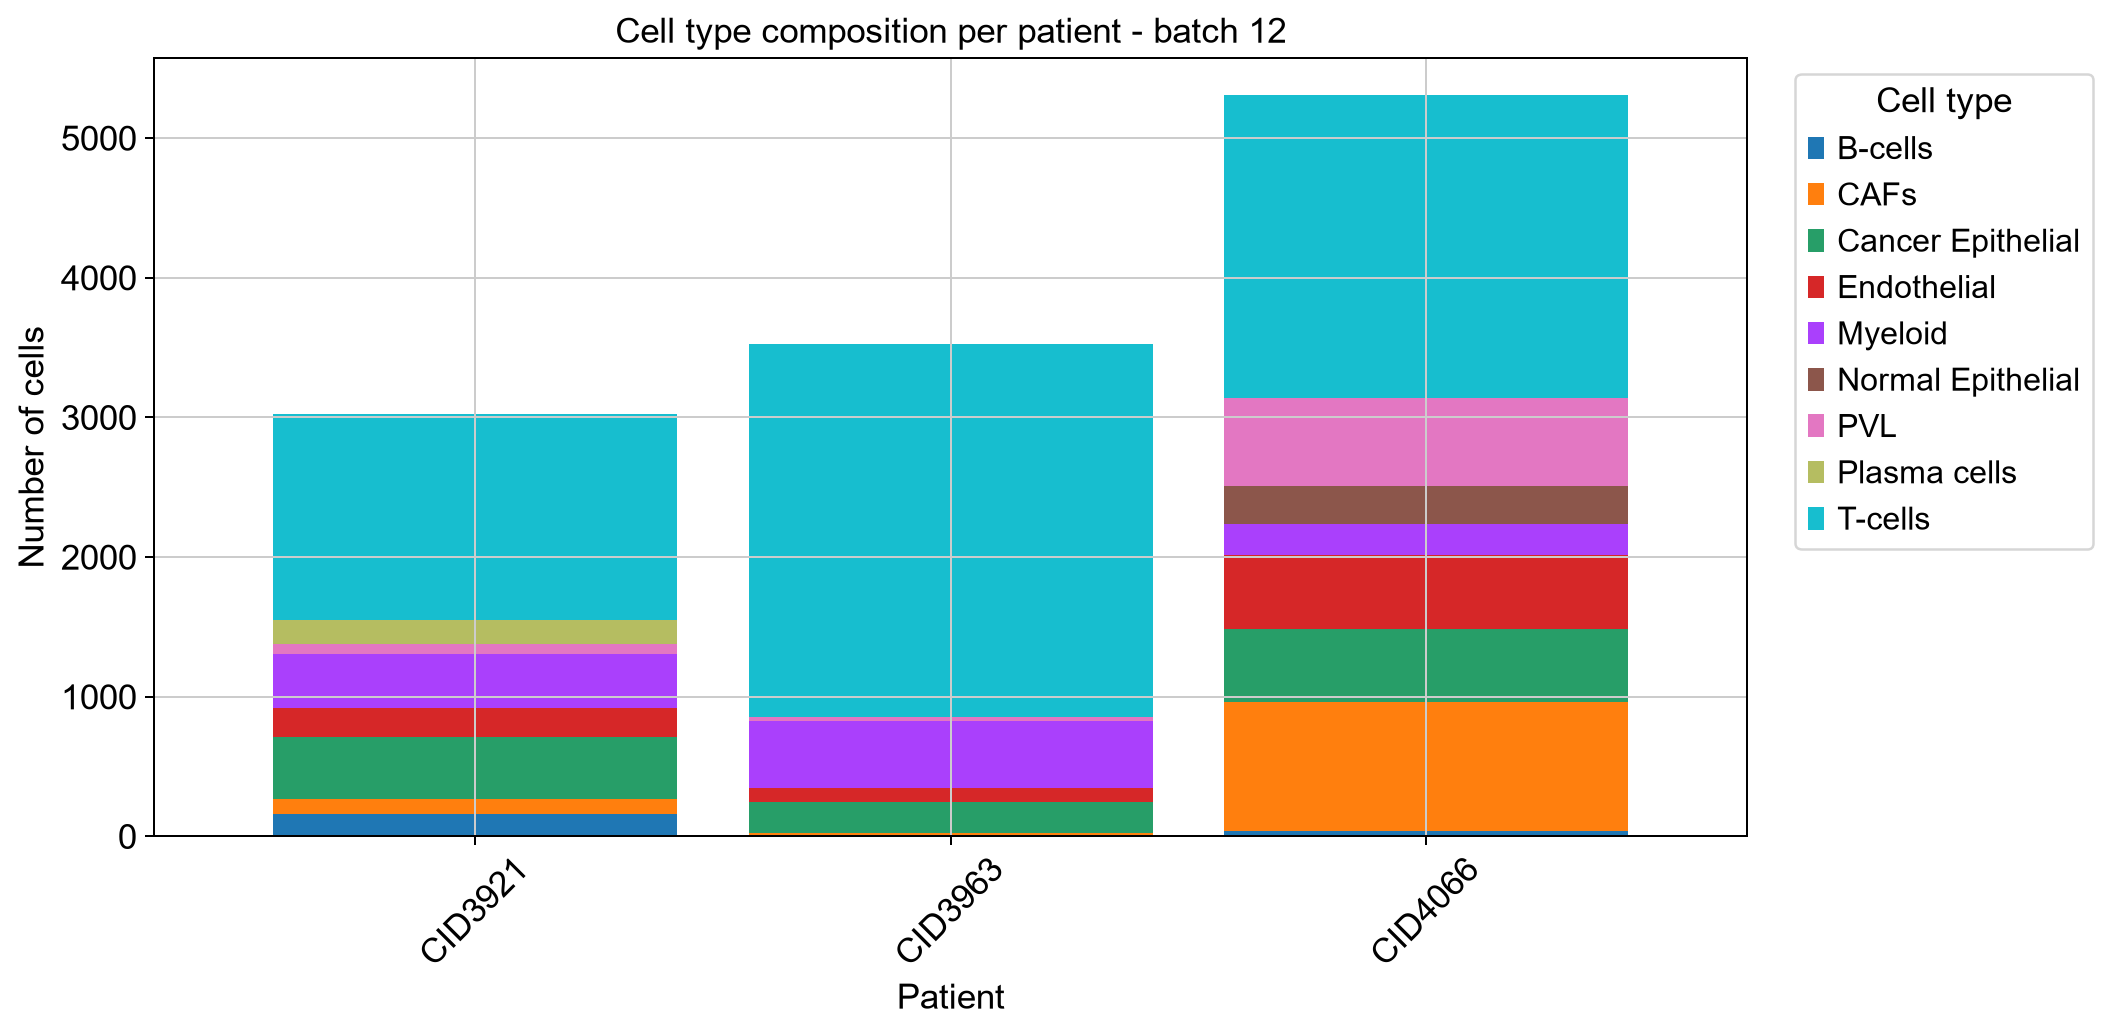

In [27]:
# Gráfico de barras apiladas: número de células
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.set_title("Cell type composition per patient - batch 12")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Entrenar solo con las T-cells, myleoids y cancer epithelial

In [33]:
patient_subtypes = (
    adata_batch12.obs[["patient", "subtype"]]
    .drop_duplicates()
    .sort_values("patient")
)

display(patient_subtypes)

,patient,subtype
CID3921_AAAGATGGTGAGGCTA,CID3921,HER2+
CID3963_AACTCCCCAGCTCGAC,CID3963,TNBC
CID4066_ACTGCTCTCTCGATGA,CID4066,HER2+


En este batch solo tengo 2 subtipos de cáncer diferentes.

HER2+ y TNBC

In [ ]:
n_latent = 10 # Ver si cambiar este número afecta a nuestros análisis
gene_likelihood = "nb"
path = MODELS_DIR / "batch12_nb"

# Configurar scVI usando directamente adata.X
scvi.model.SCVI.setup_anndata(adata_batch12)
# Crear modelo
model_batch12 = scvi.model.SCVI(adata_batch12,n_latent=n_latent, gene_likelihood=gene_likelihood)
# Entrenar
model_batch12.train(max_epochs=None, early_stopping=True)

In [37]:
model_batch12.save(path, overwrite=True)

In [38]:
# Obtener espacio latente
adata_batch12.obsm["X_scVI_batch12"] = (model_batch12.get_latent_representation())

In [ ]:

# Calcular vecinos y UMAP
sc.pp.neighbors(
    adata_batch12,
    use_rep="X_scVI_batch12",
    n_neighbors=30
)

sc.tl.umap(adata_batch12)

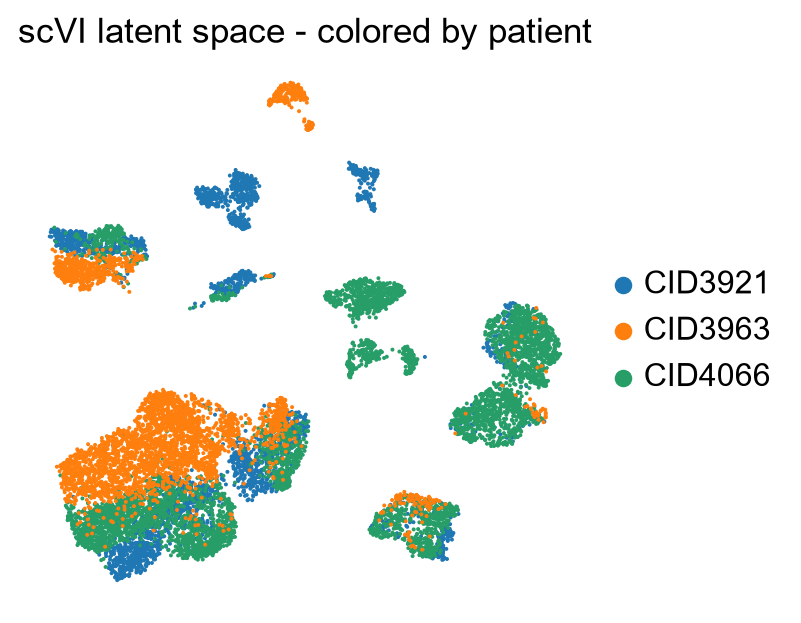

In [40]:
sc.pl.umap(
    adata_batch12,
    color="patient",
    title="scVI latent space - colored by patient",
    frameon=False
)

Seguramente  donde hay puntos de todos los colores sean los tipos de células como Tcells, Myleoids y CAFs y como vemos, tienen un comportamiento similar pero sí podemos captar clusters dentro de cada propio tipo por paciente.

Es decir, podemos ver que cada célula de cada paciente se comporta de manera "diferente".

Necesitamos métricas:

Entropía sobre un tipo de célula a ver si es capaz de decirnos si se puede distinguir el comportamiento de este tipo de células por paciente.

CID3921 - HER2+

CID3963 - TNBC

CID4066 - HER2+

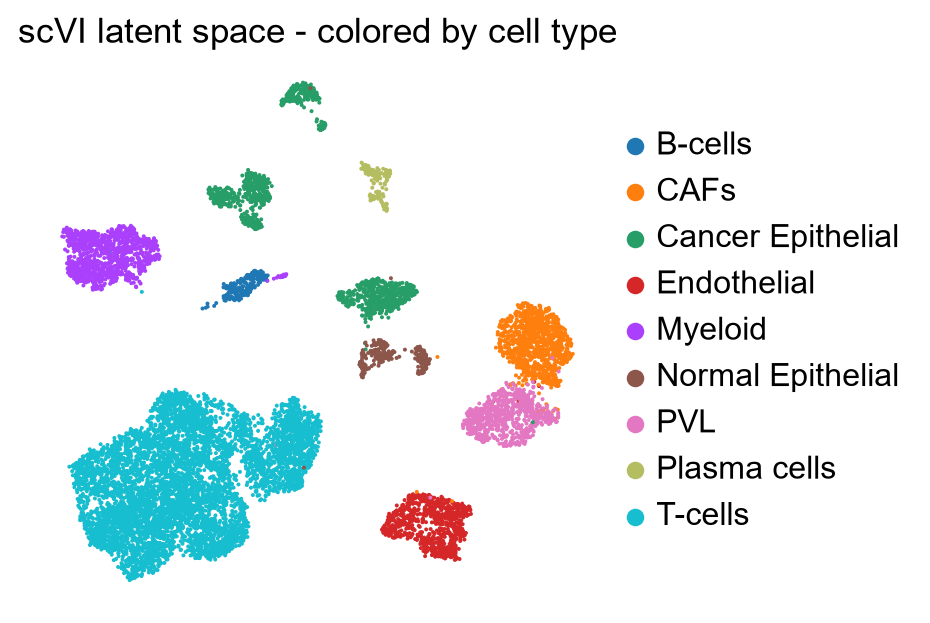

In [41]:
sc.pl.umap(
    adata_batch12,
    color="celltype",
    title="scVI latent space - colored by cell type",
    frameon=False
)


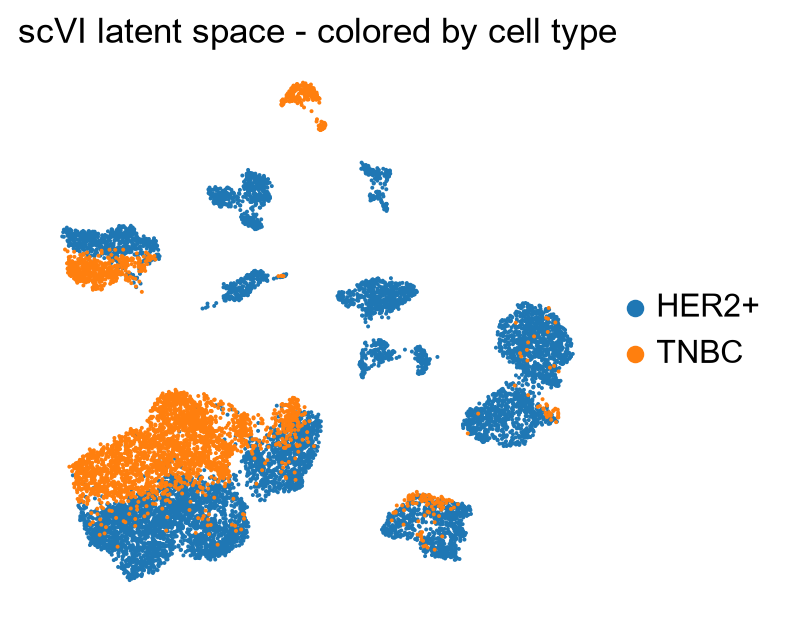

In [ ]:
sc.pl.umap(
    adata_batch12,
    color="subtype",
    title="scVI latent space - colored by subtype",
    frameon=False
)

Efectivamente, podemos intuir que un comportamiento de Tcells, myleoids, y Cafs nos puede decir el subtipo tumoral.

Métricas.

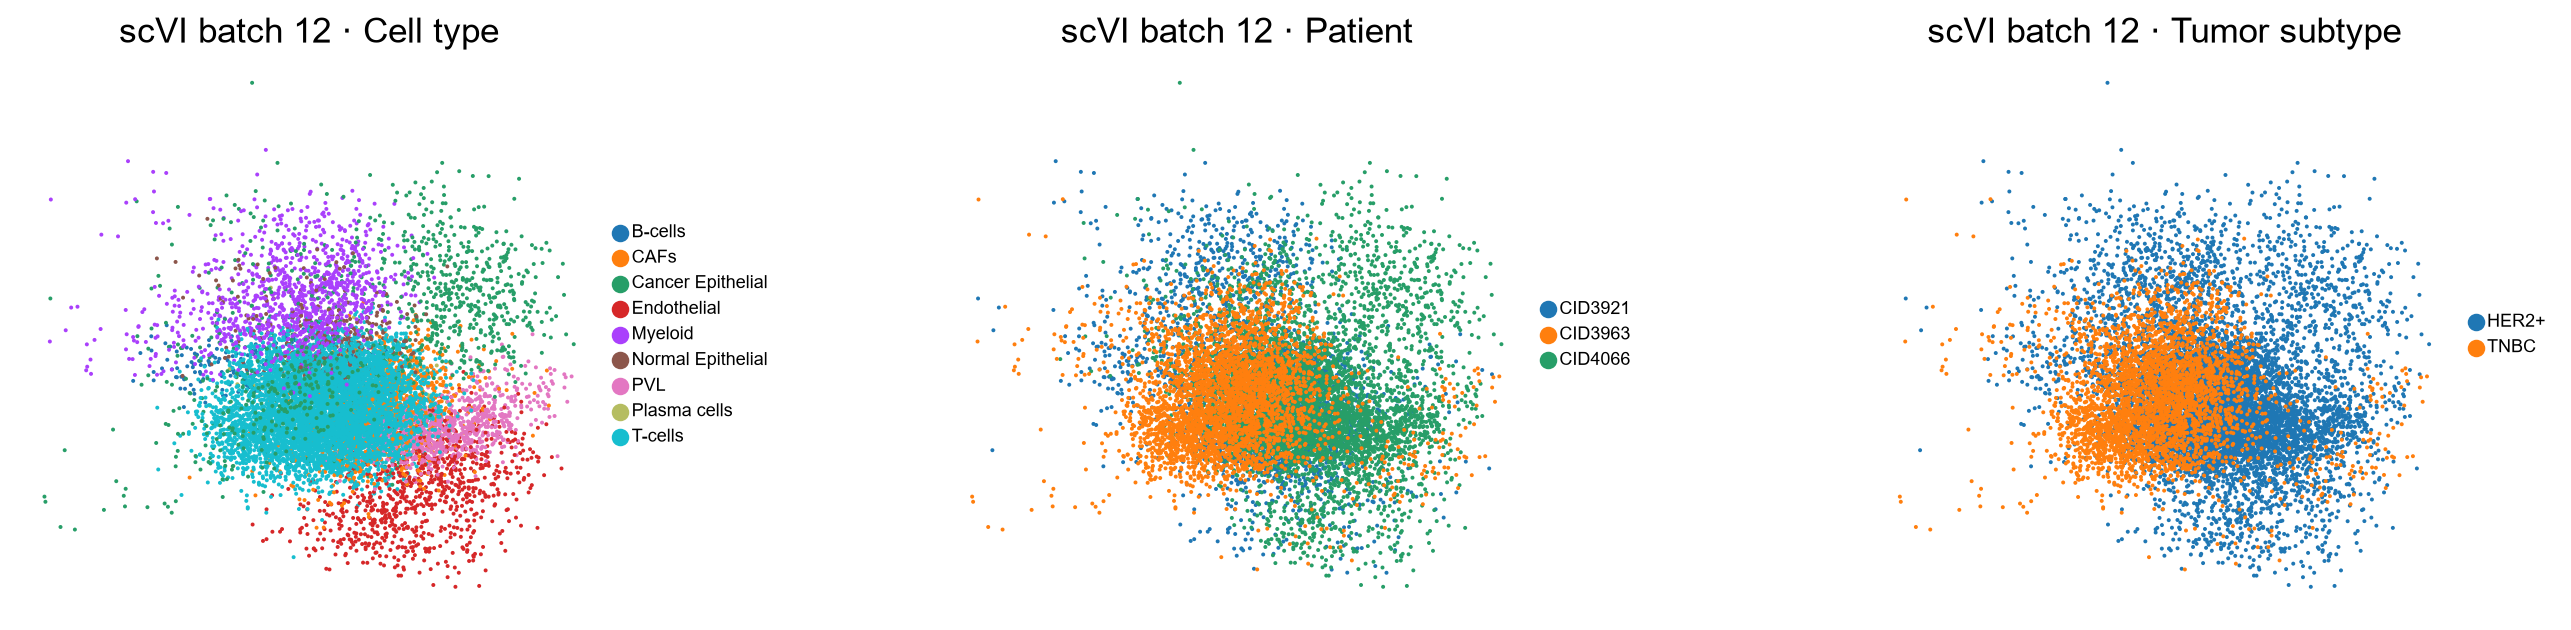

In [60]:
sc.pl.embedding(
    adata_batch12,
    basis="scVI_batch12",
    color=["celltype", "patient", "subtype"],
    wspace=0.45,
    legend_fontsize=7,
    title=[
        "scVI batch 12 · Cell type",
        "scVI batch 12 · Patient",
        "scVI batch 12 · Tumor subtype"
    ]
)

In [45]:

def calculate_entropy_by_group(adata, latent_key, group_key, donor_key="donor_id", k=30):

    results = []

    for group in adata.obs[group_key].dropna().unique():

        mask = (
            adata.obs[group_key].to_numpy() == group
        )

        Z_group = adata.obsm[latent_key][mask]

        donors_group = (
            adata.obs.loc[mask, donor_key]
            .astype(str)
            .to_numpy()
        )

        n_donors_group = len(np.unique(donors_group))

        if n_donors_group < 2 or len(donors_group) < 3:
            continue

        k_group = min(k, len(donors_group) - 1)

        nn = NearestNeighbors(
            n_neighbors=k_group + 1,
            metric="euclidean"
        )

        nn.fit(Z_group)
        indices = nn.kneighbors(Z_group, return_distance=False)

        for i in range(len(donors_group)):

            neighbor_idx = indices[i]
            neighbor_idx = neighbor_idx[neighbor_idx != i][:k_group]

            neighbor_donors = donors_group[neighbor_idx]

            _, counts = np.unique(
                neighbor_donors,
                return_counts=True
            )

            p = counts / counts.sum()

            H = -np.sum(p * np.log(p))

            H_norm = H / np.log(n_donors_group)

            results.append({
                "celltype": group,
                "donor_id": donors_group[i],
                "entropy": H,
                "entropy_norm": H_norm
            })

    return pd.DataFrame(results)


entropy_celltype = calculate_entropy_by_group(
    adata_batch12,
    latent_key="X_scVI_batch12",
    group_key="celltype",
    donor_key="patient",
    k=30
)

entropy_summary = (
    entropy_celltype
    .groupby(["celltype", "donor_id"])
    .agg(
        mean_entropy=("entropy", "mean"),
        mean_entropy_norm=("entropy_norm", "mean")
    )
    .reset_index()
)

display(entropy_summary)


,celltype,donor_id,mean_entropy,mean_entropy_norm
0,B-cells,CID3921,0.132896,0.191728
1,B-cells,CID4066,0.618925,0.892920
2,CAFs,CID3921,0.604224,0.549989
3,CAFs,CID3963,0.530289,0.482690
4,CAFs,CID4066,0.073909,0.067275
5,Cancer Epithelial,CID3921,0.004138,0.003767
6,Cancer Epithelial,CID3963,0.000658,0.000599
7,Cancer Epithelial,CID4066,0.004152,0.003779
8,Endothelial,CID3921,0.648188,0.590006
9,Endothelial,CID3963,0.800661,0.728793


Centrarnos en el tipo de célula donde tengan un número de ellas similar (T-cells, Myleoids, Endothelial, Cancer).

T-Cells: El paciente 3963 tiene menor valor de entropía, es decir que en ese tipo de células, lo que más se encuentra son células de ese paciente. Este paciente es el único con cancer subtipo TNBC, por lo que sí podemos ver una separación un poco más clara entre los pacientes de este batch.
Para los otros pacientes el valor es un poco más alto, estos valores son orientativos ya que no tienen la misma cantidad de células cada paciente.

¿Es correcto coger un número de células concreot por cada paciente o estaríamos perdiendo información?

¿Qué tal analizar cada gen?

Myleoids: Vemos el mismo comportamiento

Endothelial: Este es el ejemplo perfecto de por qué tampoco nos podemos fiar del todo de la entropía, es orientativo.

En este caso para nuestro paciente 3963 (TNBC) tenemos un valor altísimo, pero si vemos en el gráfico anterior donde veíamos el número de células por paciente, este es el que menos tenía.


In [46]:
# Batch 13

adata_batch13 = adata[
    adata.obs["batch_run"].astype(str) == "13"
].copy()

print("Número de células:", adata_batch13.n_obs)
print("Número de pacientes:",
      adata_batch13.obs["patient"].nunique())

print("\nCélulas por paciente:")
print(adata_batch13.obs["patient"].value_counts())

Número de células: 9136
Número de pacientes: 3

Células por paciente:
patient
CID3586    6178
CID3948    2327
CID3941     631
Name: count, dtype: int64


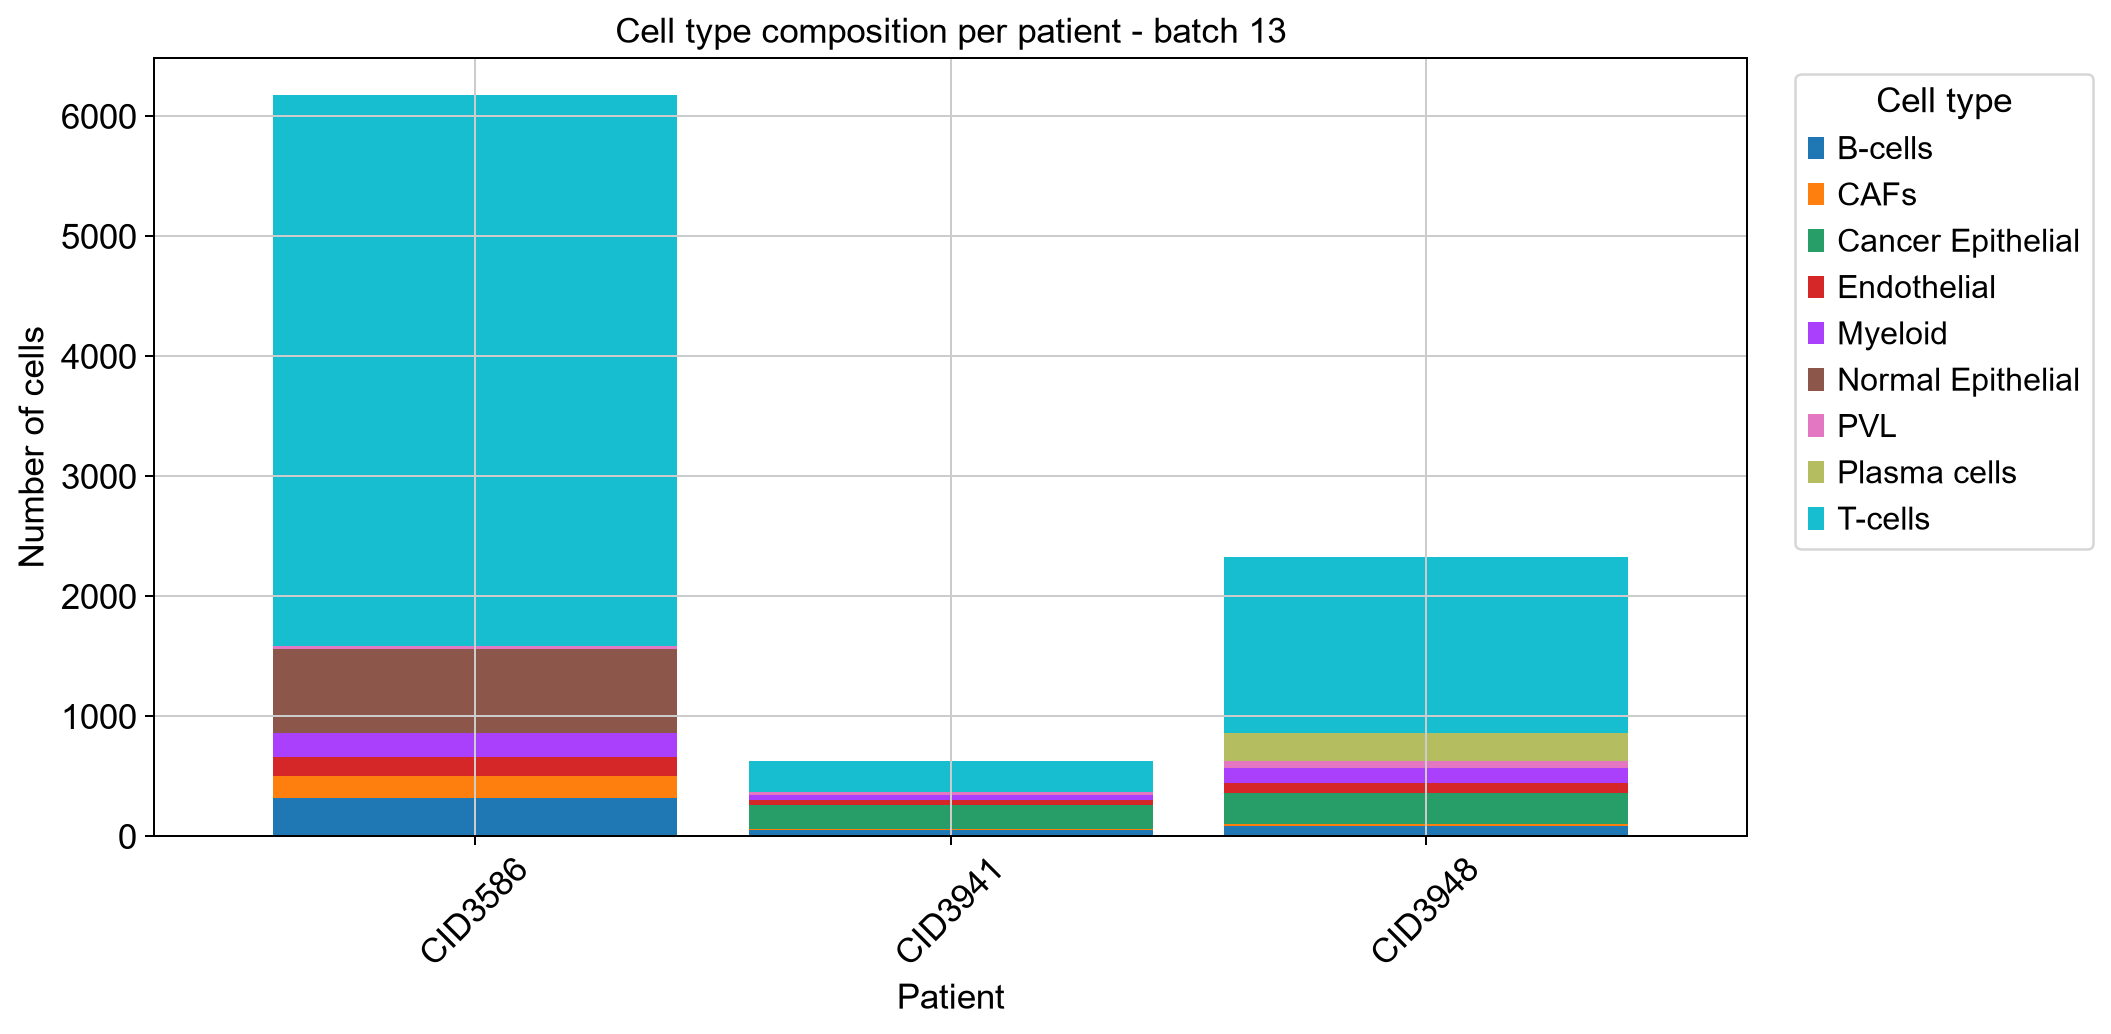

In [63]:
# Tabla de número de células
cell_counts = pd.crosstab(
    adata_batch13.obs["patient"],
    adata_batch13.obs["celltype"]
)

# Gráfico de barras apiladas: número de células
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.set_title("Cell type composition per patient - batch 13")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
patient_subtypes = (
    adata_batch12.obs[["patient", "subtype"]]
    .drop_duplicates()
    .sort_values("patient")
)

display(patient_subtypes)

,patient,subtype
CID3921_AAAGATGGTGAGGCTA,CID3921,HER2+
CID3963_AACTCCCCAGCTCGAC,CID3963,TNBC
CID4066_ACTGCTCTCTCGATGA,CID4066,HER2+


No es el mejor grupo para analizar.

Probamos con el último batch run de 3 personas (16), y pensamos cómo podemos actuar con personas de diferentes batches.

Por ejemplo, coger a pacientes con características similares (mismo subtipo de cáncer y número de células parecido) y analizar con y sin batch correction de batch_run/patient.

In [49]:
# Batch 16

adata_batch16 = adata[
    adata.obs["batch_run"].astype(str) == "16"
].copy()

print("Número de células:", adata_batch16.n_obs)
print("Número de pacientes:",
      adata_batch16.obs["patient"].nunique())

print("\nCélulas por paciente:")
print(adata_batch16.obs["patient"].value_counts())

Número de células: 5658
Número de pacientes: 3

Células por paciente:
patient
CID4040    2531
CID3838    2353
CID3946     774
Name: count, dtype: int64


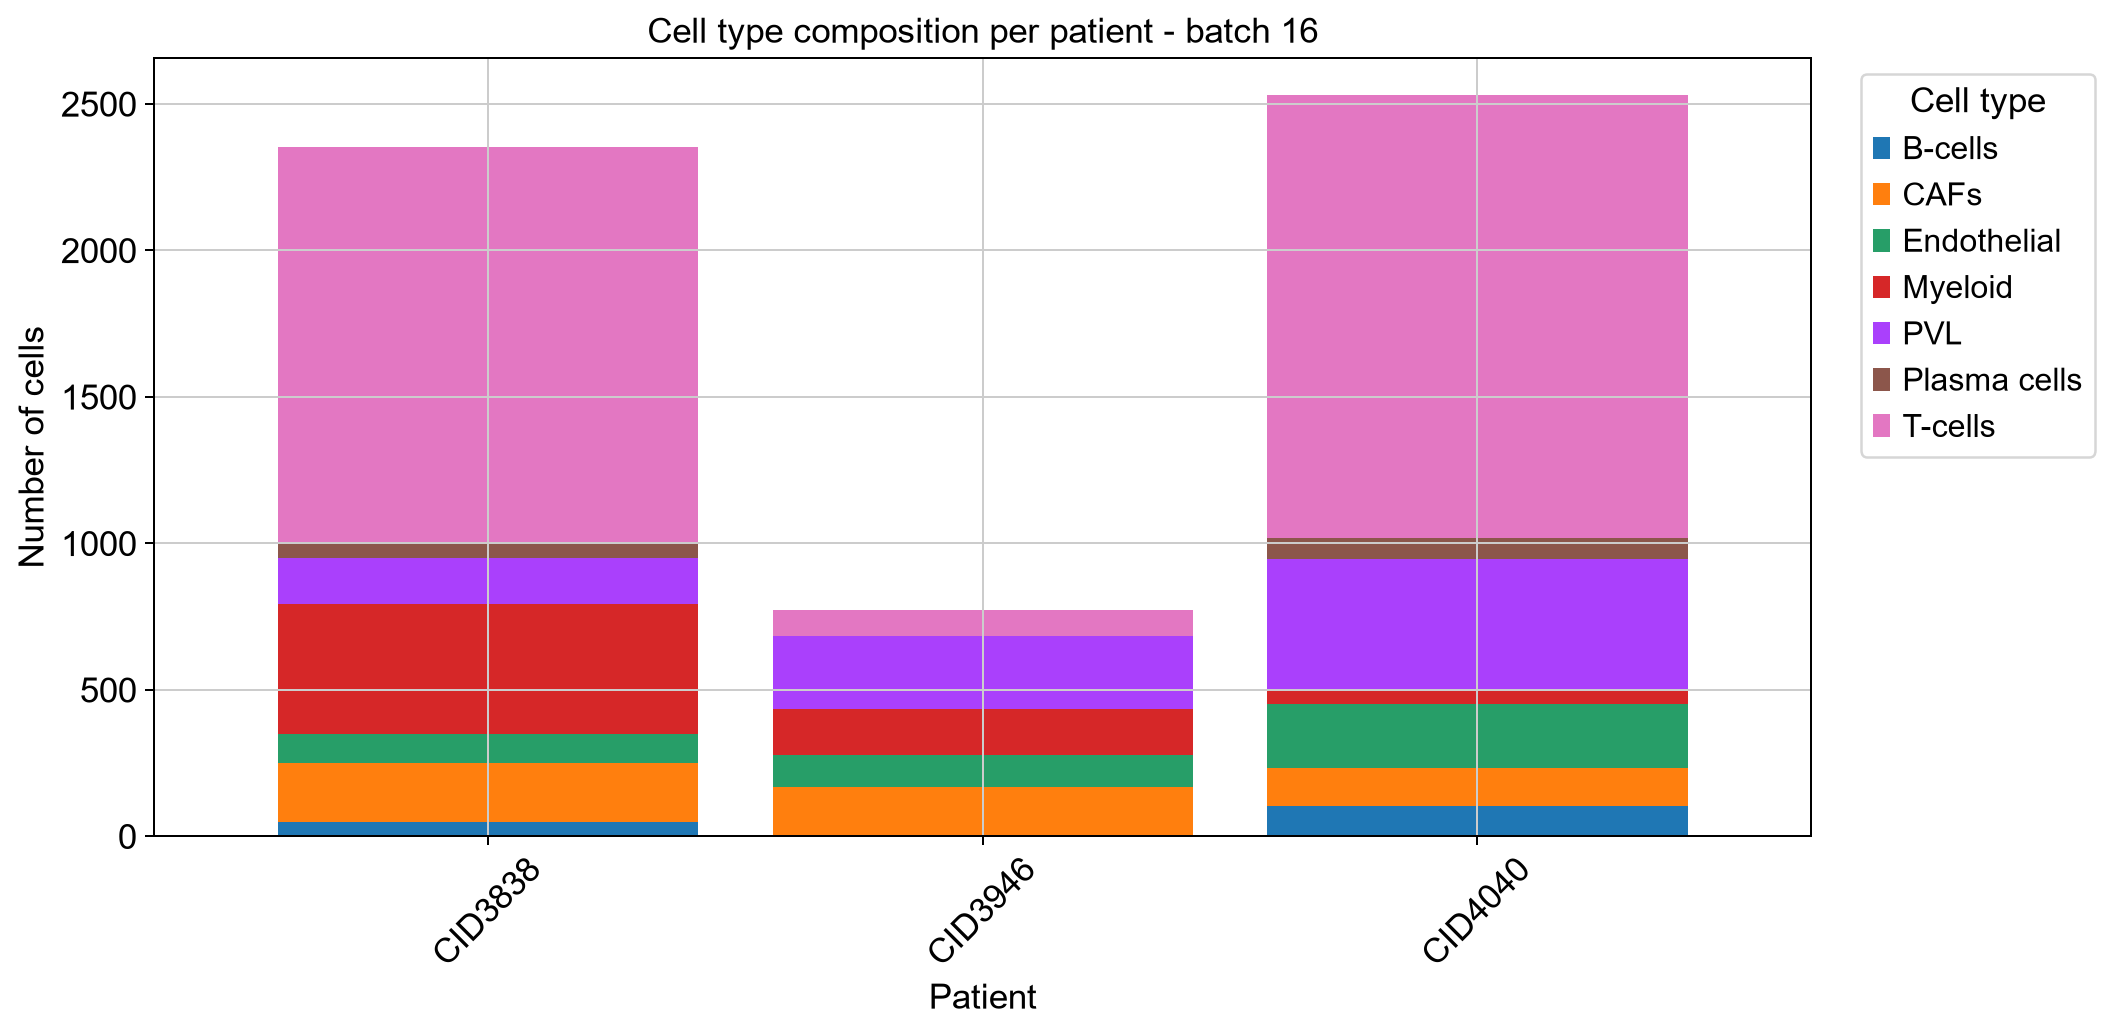

In [62]:
# Tabla de número de células
cell_counts = pd.crosstab(
    adata_batch16.obs["patient"],
    adata_batch16.obs["celltype"]
)

# Gráfico de barras apiladas: número de células
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.set_title("Cell type composition per patient - batch 16")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Podemos comparar otro tipo de células esta vez.

No tenemos Cancer Epithelial ni Normal Epithelial esta vez, hay que tener cuidado con eso porque esto cambia muchas cosas.


In [51]:
patient_subtypes = (
    adata_batch16.obs[["patient", "subtype"]]
    .drop_duplicates()
    .sort_values("patient")
)

display(patient_subtypes)

,patient,subtype
CID3838_AAACGCTAGAGCCGAT,CID3838,HER2+
CID3946_ACTGCAACAGCTACTA,CID3946,TNBC
CID4040_ACTGATGAGGCCTTCG,CID4040,ER+


Un tipo por cáncer. Nos viene perfecto para ver el comportamiento en otros tipos de células.

PVL, ENDOTHELIAL Y CAFS

In [52]:
n_latent = 10 # Ver si cambiar este número afecta a nuestros análisis
gene_likelihood = "nb"
path = MODELS_DIR / "batch16_nb"

# Configurar scVI usando directamente adata.X
scvi.model.SCVI.setup_anndata(adata_batch16)
# Crear modelo
model_batch16 = scvi.model.SCVI(adata_batch16,n_latent=n_latent, gene_likelihood=gene_likelihood)
# Entrenar
model_batch16.train(max_epochs=None, early_stopping=True)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Epoch 249/400:  62%|██████▏   | 249/400 [33:38<20:24,  8.11s/it, v_num=1, train_loss=6.54e+3]  
Monitored metric elbo_validation did not improve in the last 45 records. Best score: 6433.392. Signaling Trainer to stop.


In [53]:
model_batch16.save(path, overwrite=True)

In [54]:
# Obtener espacio latente
adata_batch16.obsm["X_scVI_batch16"] = (model_batch16.get_latent_representation())


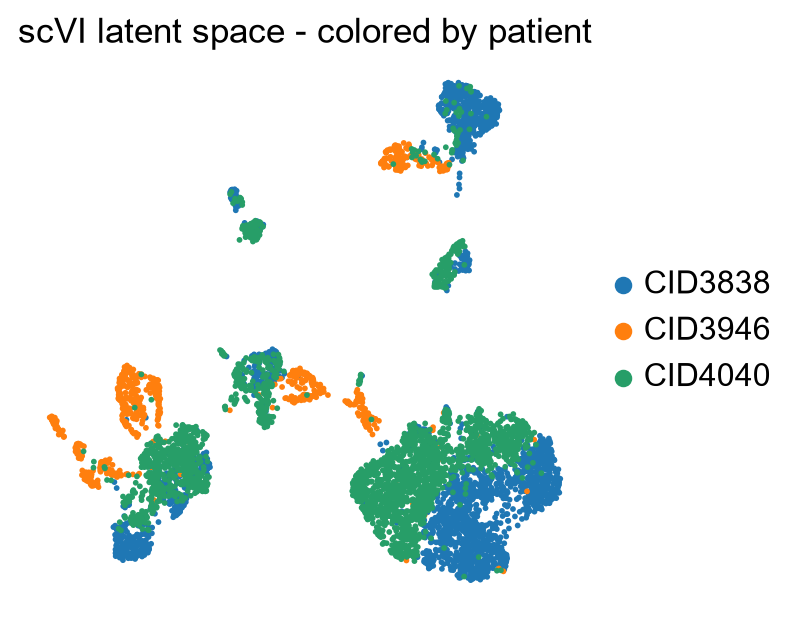

In [55]:
# Calcular vecinos y UMAP
sc.pp.neighbors(
    adata_batch16,
    use_rep="X_scVI_batch16",
    n_neighbors=30
)

sc.tl.umap(adata_batch16)

sc.pl.umap(
    adata_batch16,
    color="patient",
    title="scVI latent space - colored by patient",
    frameon=False
)


Ya sabíamos que 3946 tenía muy pocas células pero nos interesa el comportamiento de las células que hemos mencionado antes

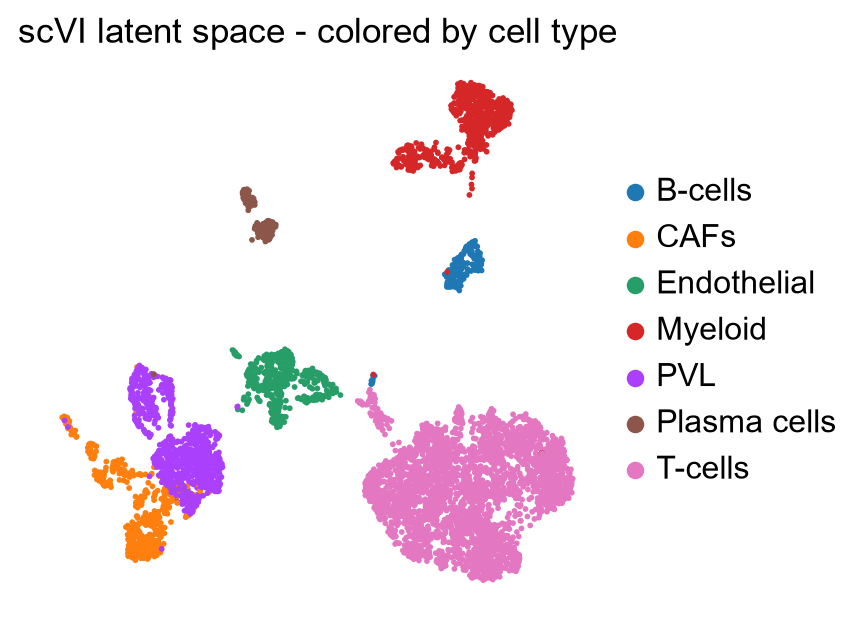

In [56]:
sc.pl.umap(
    adata_batch16,
    color="celltype",
    title="scVI latent space - colored by cell type",
    frameon=False
)


PVL: dentro del grupo morado antes diferenciábamos tres clusters, donde el verde (4040) estaba encima del azul (3838) cada uno haciendo referencia a un paciente.

Queremos ver si esta diferencia es significativa.

Entropía por célula

Endothelial: mismo caso, pacientes 4040 y 3838 se solapan

CAFs: mismo caso, pacientes 4040 y 3838 se solapan

Es decir, no solo los pacientes se solapan, sino que también PVL y CAFs se solapan. ¿Qué significa? Hay que seguir investigando.

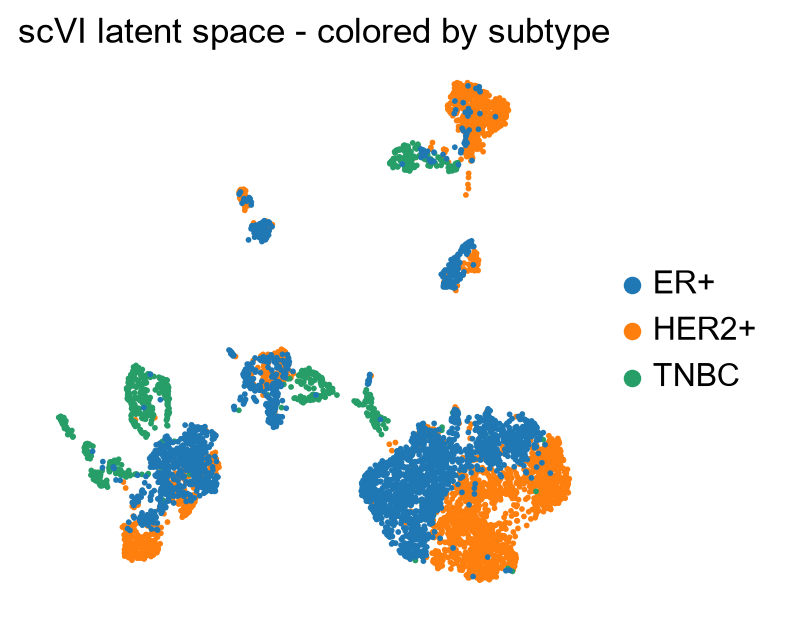

In [61]:
sc.pl.umap(
    adata_batch16,
    color="subtype",
    title="scVI latent space - colored by subtype",
    frameon=False
)

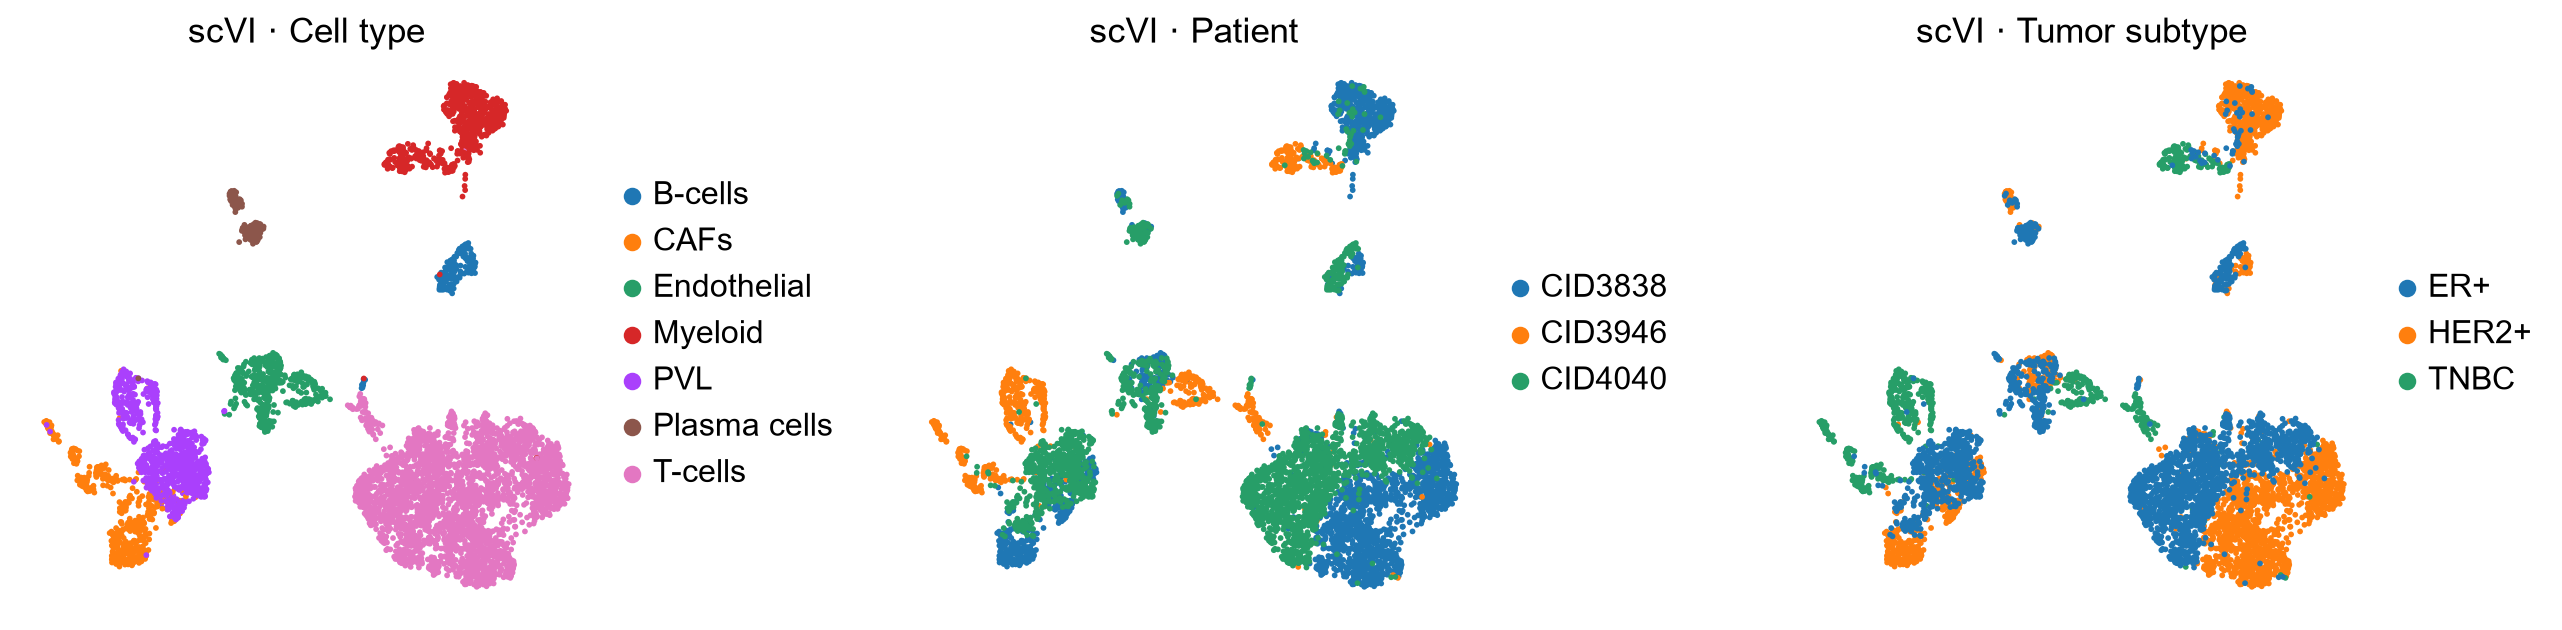

In [80]:
sc.pp.neighbors(
    adata_batch16,
    use_rep="X_scVI_batch16",
    n_neighbors=30
)

sc.tl.umap(adata_batch16)


sc.pl.umap(
    adata_batch16,
    color=["celltype", "patient", "subtype"],
    wspace=0.4,
    frameon=False,
    title=[
        "scVI · Cell type",
        "scVI · Patient",
        "scVI · Tumor subtype"
    ]
)

En el sector de la esquina inferior izquierda apenas podemos deducir nada. Este sector es el que más problemas nos está dando, necesitamos métricas para explicar qué está pasando.

In [ ]:
# Métricas
# Entropía para PVL y CAFs

Sí que podemos concluir que el batch_run es algo a tener en cuenta para la correción de pacientes.

¿Y si le damos la información de las células usando scanvi?

In [75]:
n_latent = 10 # Ver si cambiar este número afecta a nuestros análisis
gene_likelihood = "nb"
path = MODELS_DIR / "scanvi_batch16_nb"

# Inicializar scANVI desde scVI
scanvi_model_batch16 = scvi.model.SCANVI.from_scvi_model(
    model_batch16,
    labels_key="celltype",
    unlabeled_category="Unknown"
)

# Entrenar scANVI
scanvi_model_batch16.train(
    max_epochs=100,
    n_samples_per_label=100,
    early_stopping=True
)

INFO     Training for 100 epochs.                                                                                  


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
c:\Users\sampe\anaconda3\envs\scvi_latest\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Epoch 46/100:  46%|████▌     | 46/100 [10:30<12:20, 13.71s/it, v_num=1, train_loss=6.52e+3]
Monitored metric elbo_validation did not improve in the last 45 records. Best score: 6444.979. Signaling Trainer to stop.


In [76]:
# Obtener representación latente
adata_batch16.obsm["X_scANVI_batch16"] = (
    scanvi_model_batch16.get_latent_representation()
)

# Guardar modelo
scanvi_model_batch16.save(path,overwrite=True)


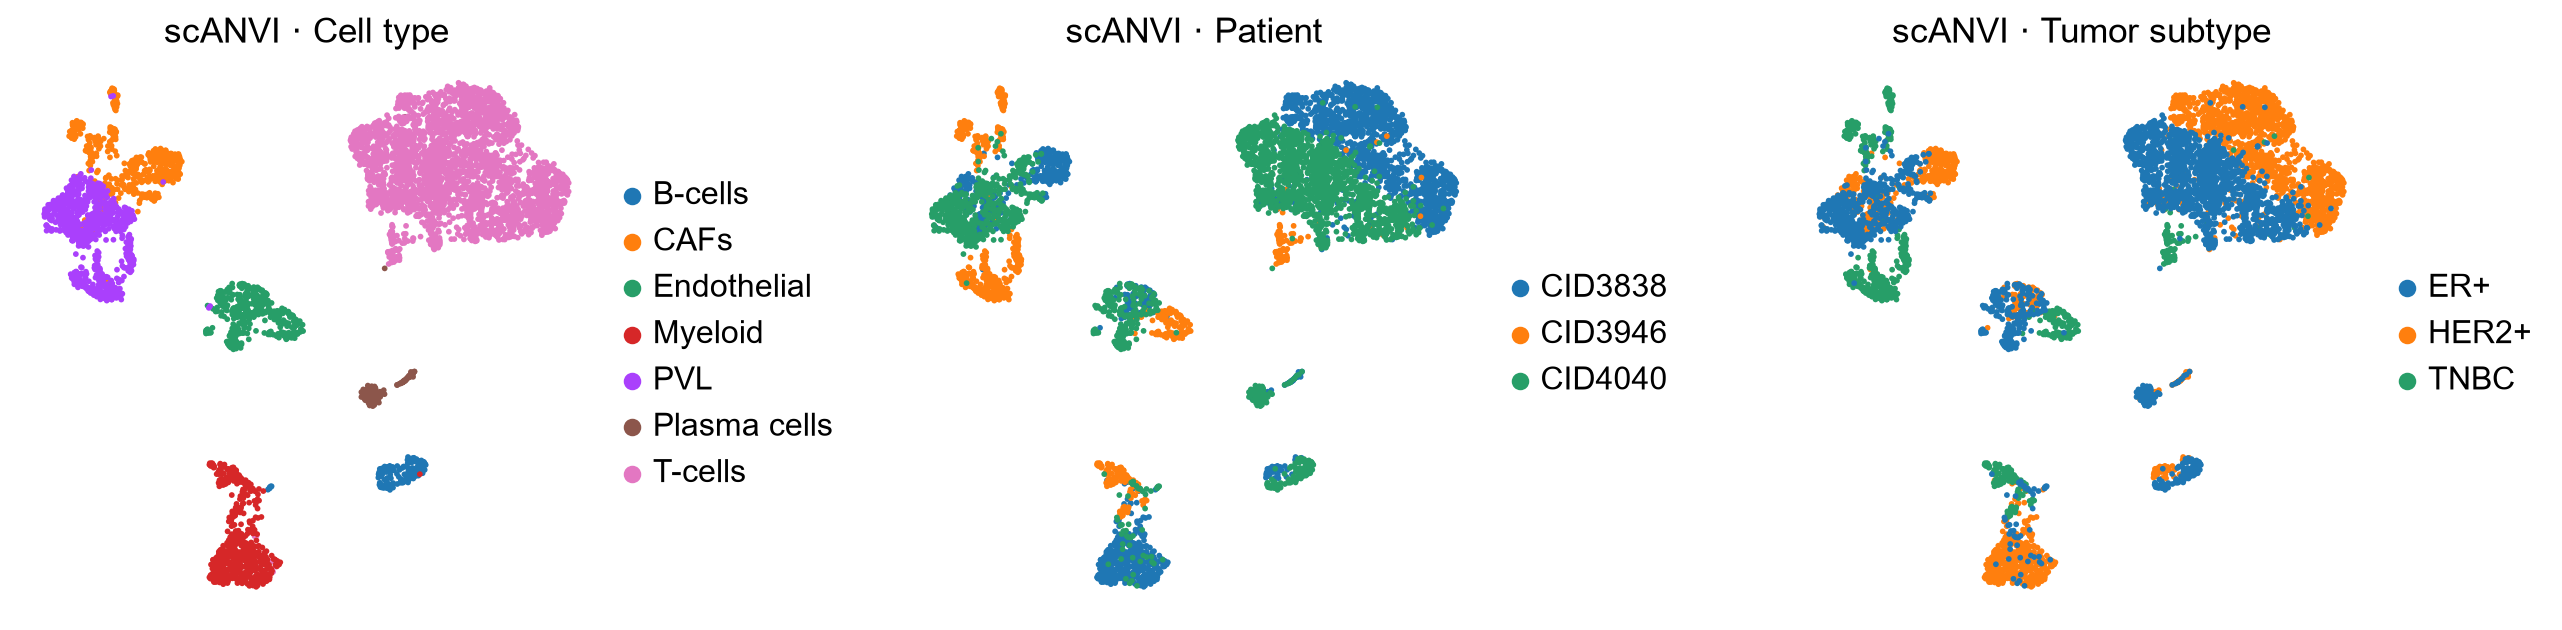

In [78]:
sc.pp.neighbors(
    adata_batch16,
    use_rep="X_scANVI_batch16",
    n_neighbors=30
)

sc.tl.umap(adata_batch16)

sc.pl.umap(
    adata_batch16,
    color=["celltype", "patient", "subtype"],
    wspace=0.4,
    frameon=False,
    title=[
        "scANVI · Cell type",
        "scANVI · Patient",
        "scANVI · Tumor subtype"
    ]
)

In [ ]:
# Visualmente parece que scANVI NO mejora la separación de tipos celulares y pacientes, pero necesitamos métricas. 

# Calcular entropía para PVL y CAFs, ARI y comparar con SCVI y PCA

# Entropía por célula, si las células vecinas son del mismo tipo.

# Esto es interesante ya que vemos que lagunas células no son tan fácilas de separar.
# Si no lo son tendremos que averiguar por qué, investigar genes, subtipo, etc... algo que tengan en común 
# Que haga que vayan juntas.

# Entropía por paciente, si las células vecinas son del mismo paciente.

**IMPORTANTE:** No estamos teniendo en cuenta genes altamente variables (HVG), por lo que hay que investigar si es correcto o aplicar un filtro.

Ahora vamos con la idea que he propuesto antes.

"Coger a pacientes con características similares (mismo subtipo de cáncer y número de células parecido) y analizar con y sin batch correction de batch_run/patient."

A ver cómo es capaz de separar por paciente.

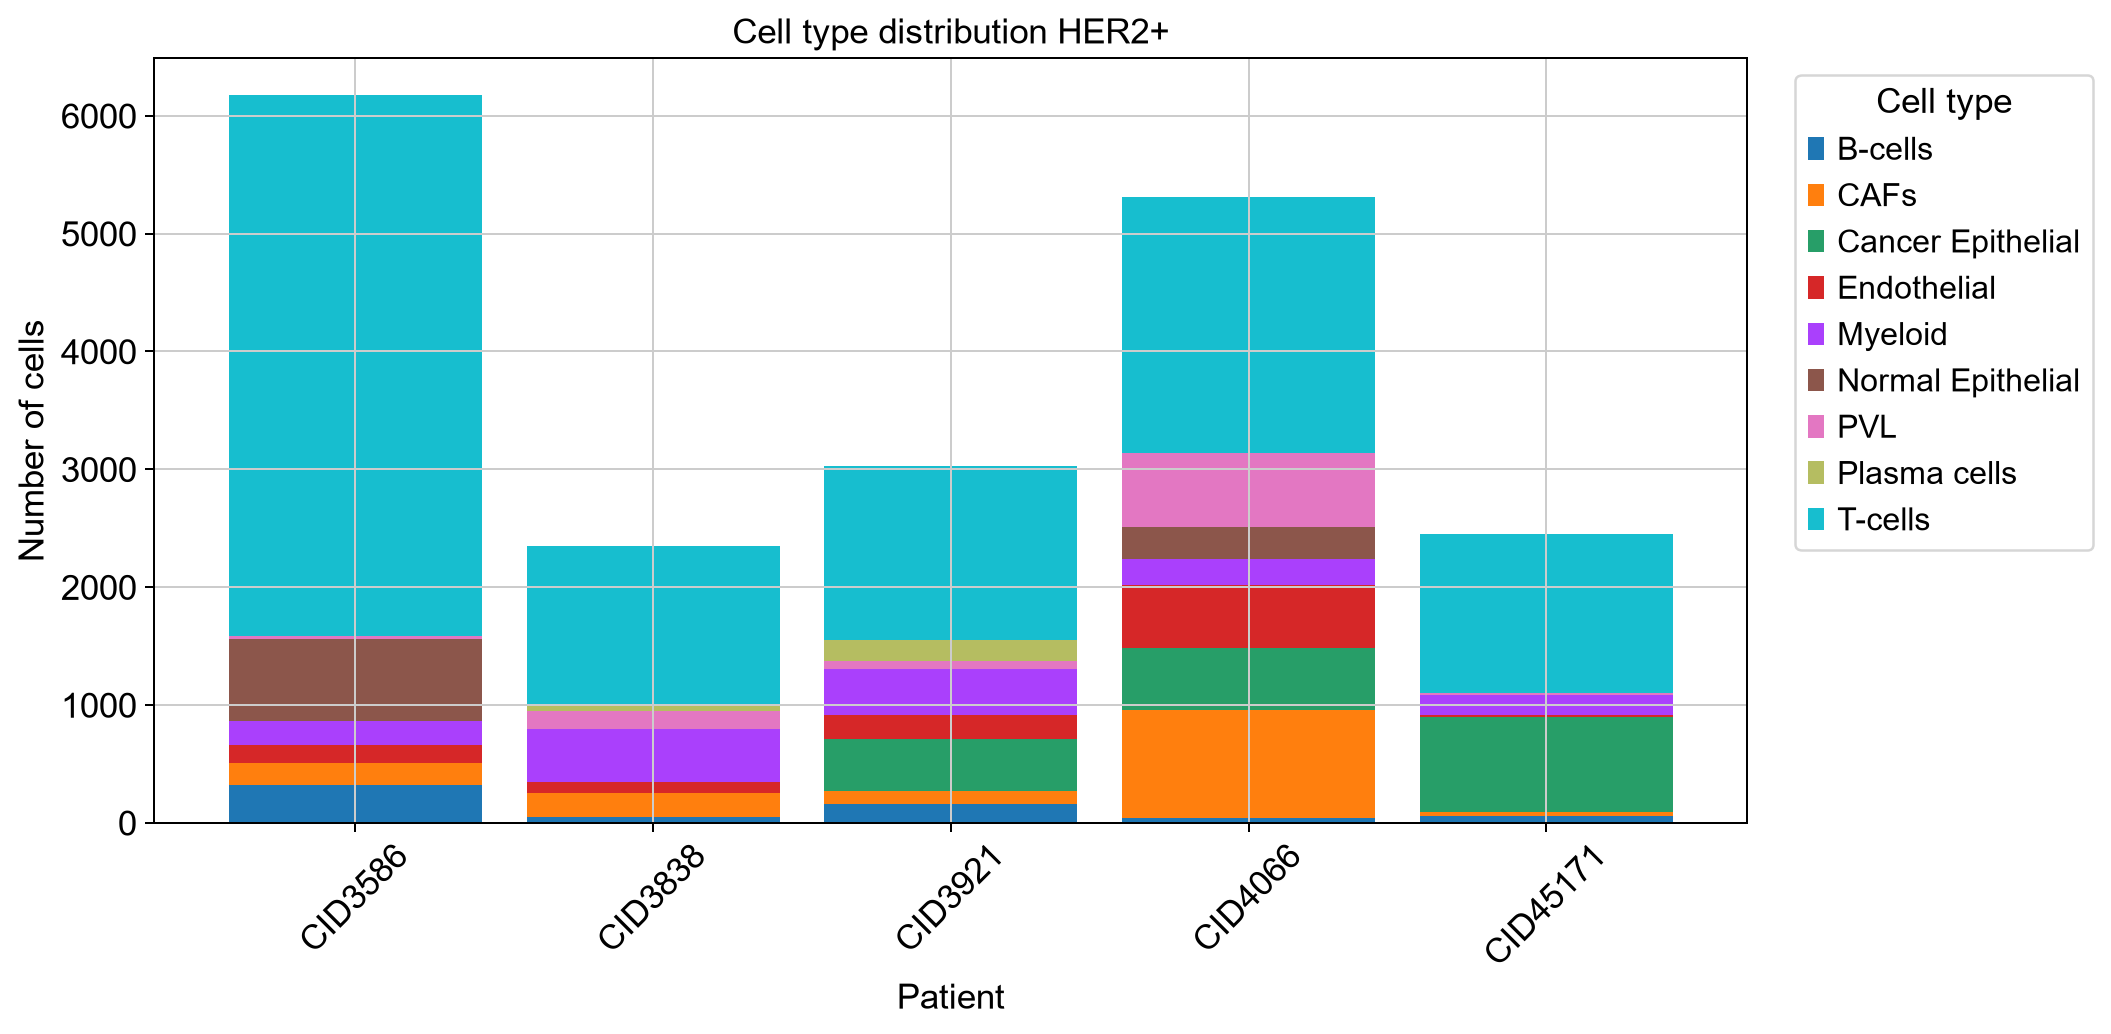

In [73]:
adata_subtype_h = adata[
    adata.obs["subtype"] == "HER2+"
].copy()

cell_counts = pd.crosstab(
    adata_subtype_h.obs["patient"],
    adata_subtype_h.obs["celltype"]
)

# Plot
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_title("Cell type distribution HER2+")
ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

...

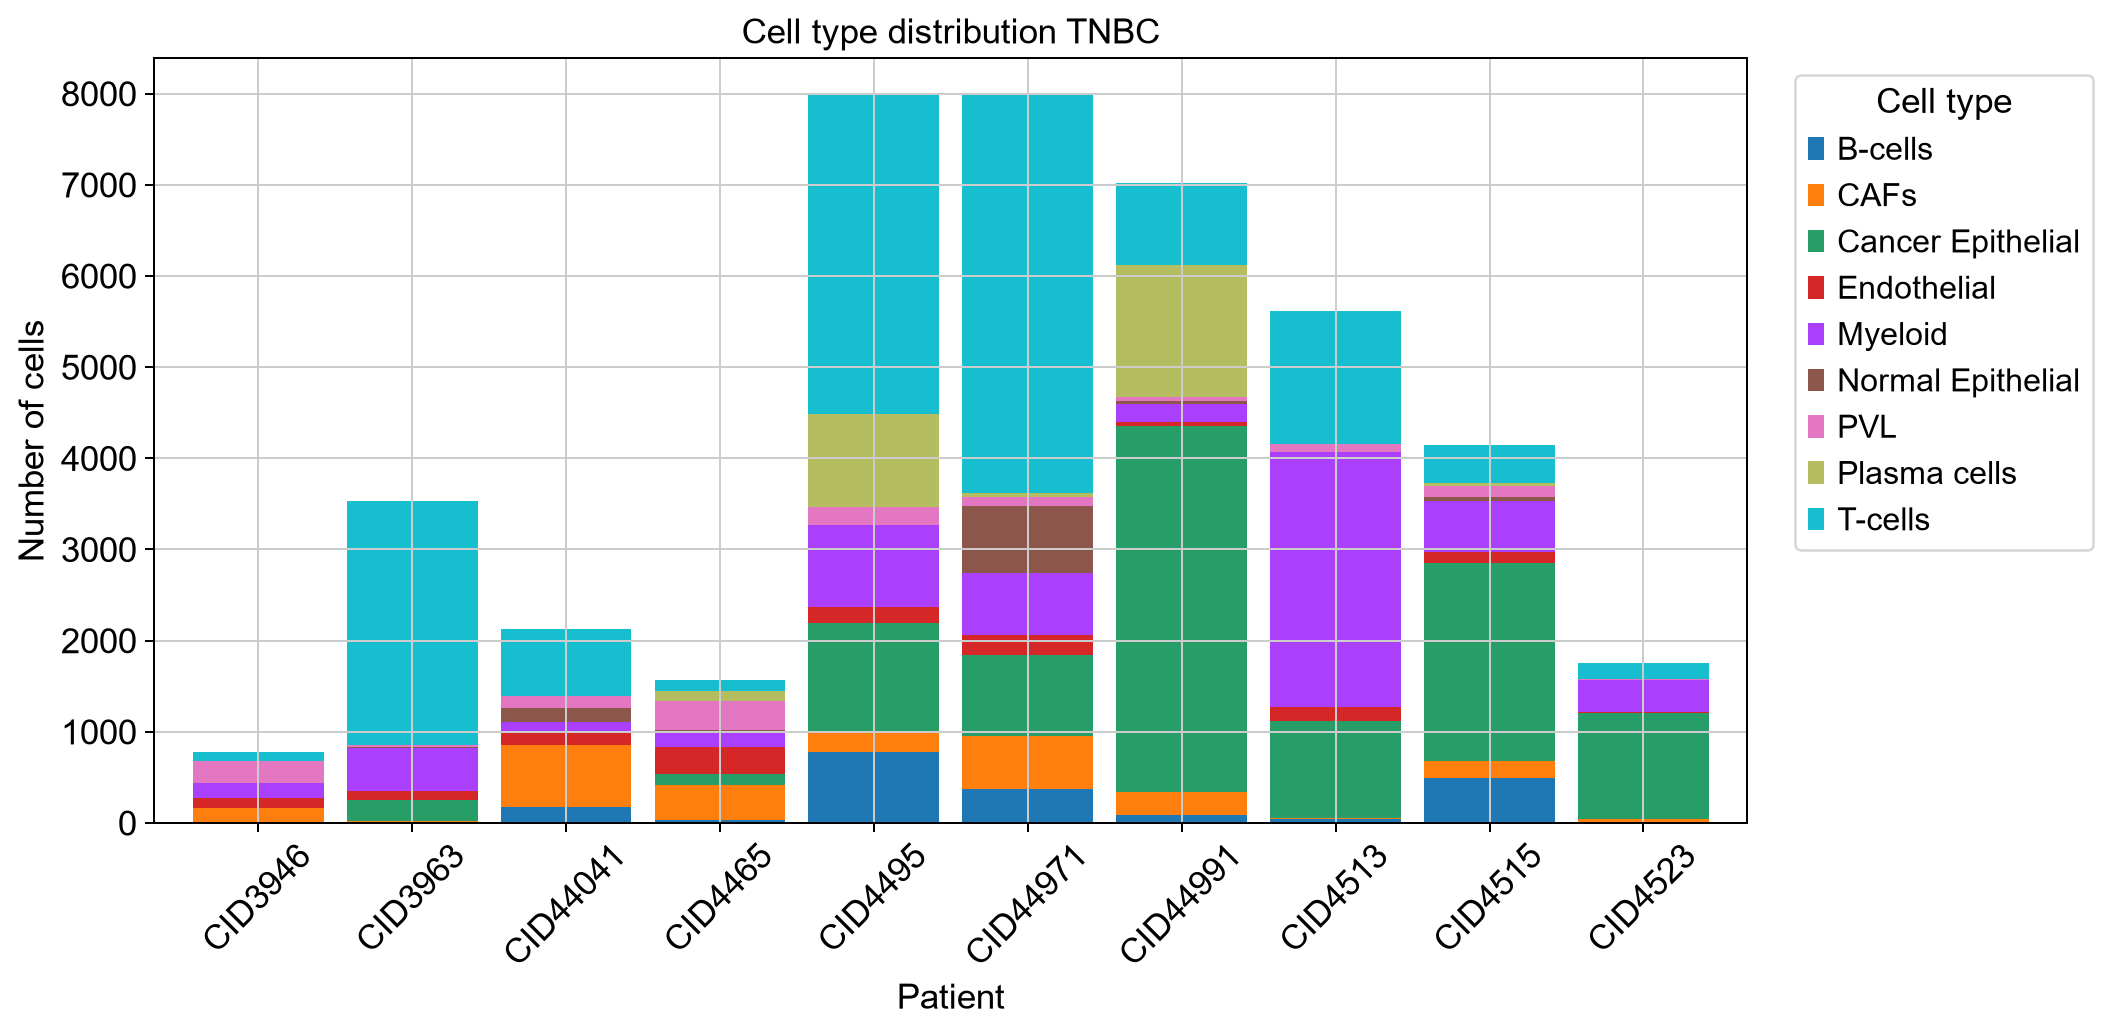

In [71]:
adata_subtype_t = adata[
    adata.obs["subtype"] == "TNBC"
].copy()

cell_counts = pd.crosstab(
    adata_subtype_t.obs["patient"],
    adata_subtype_t.obs["celltype"]
)

# Plot
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_title("Cell type distribution TNBC")
ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

...

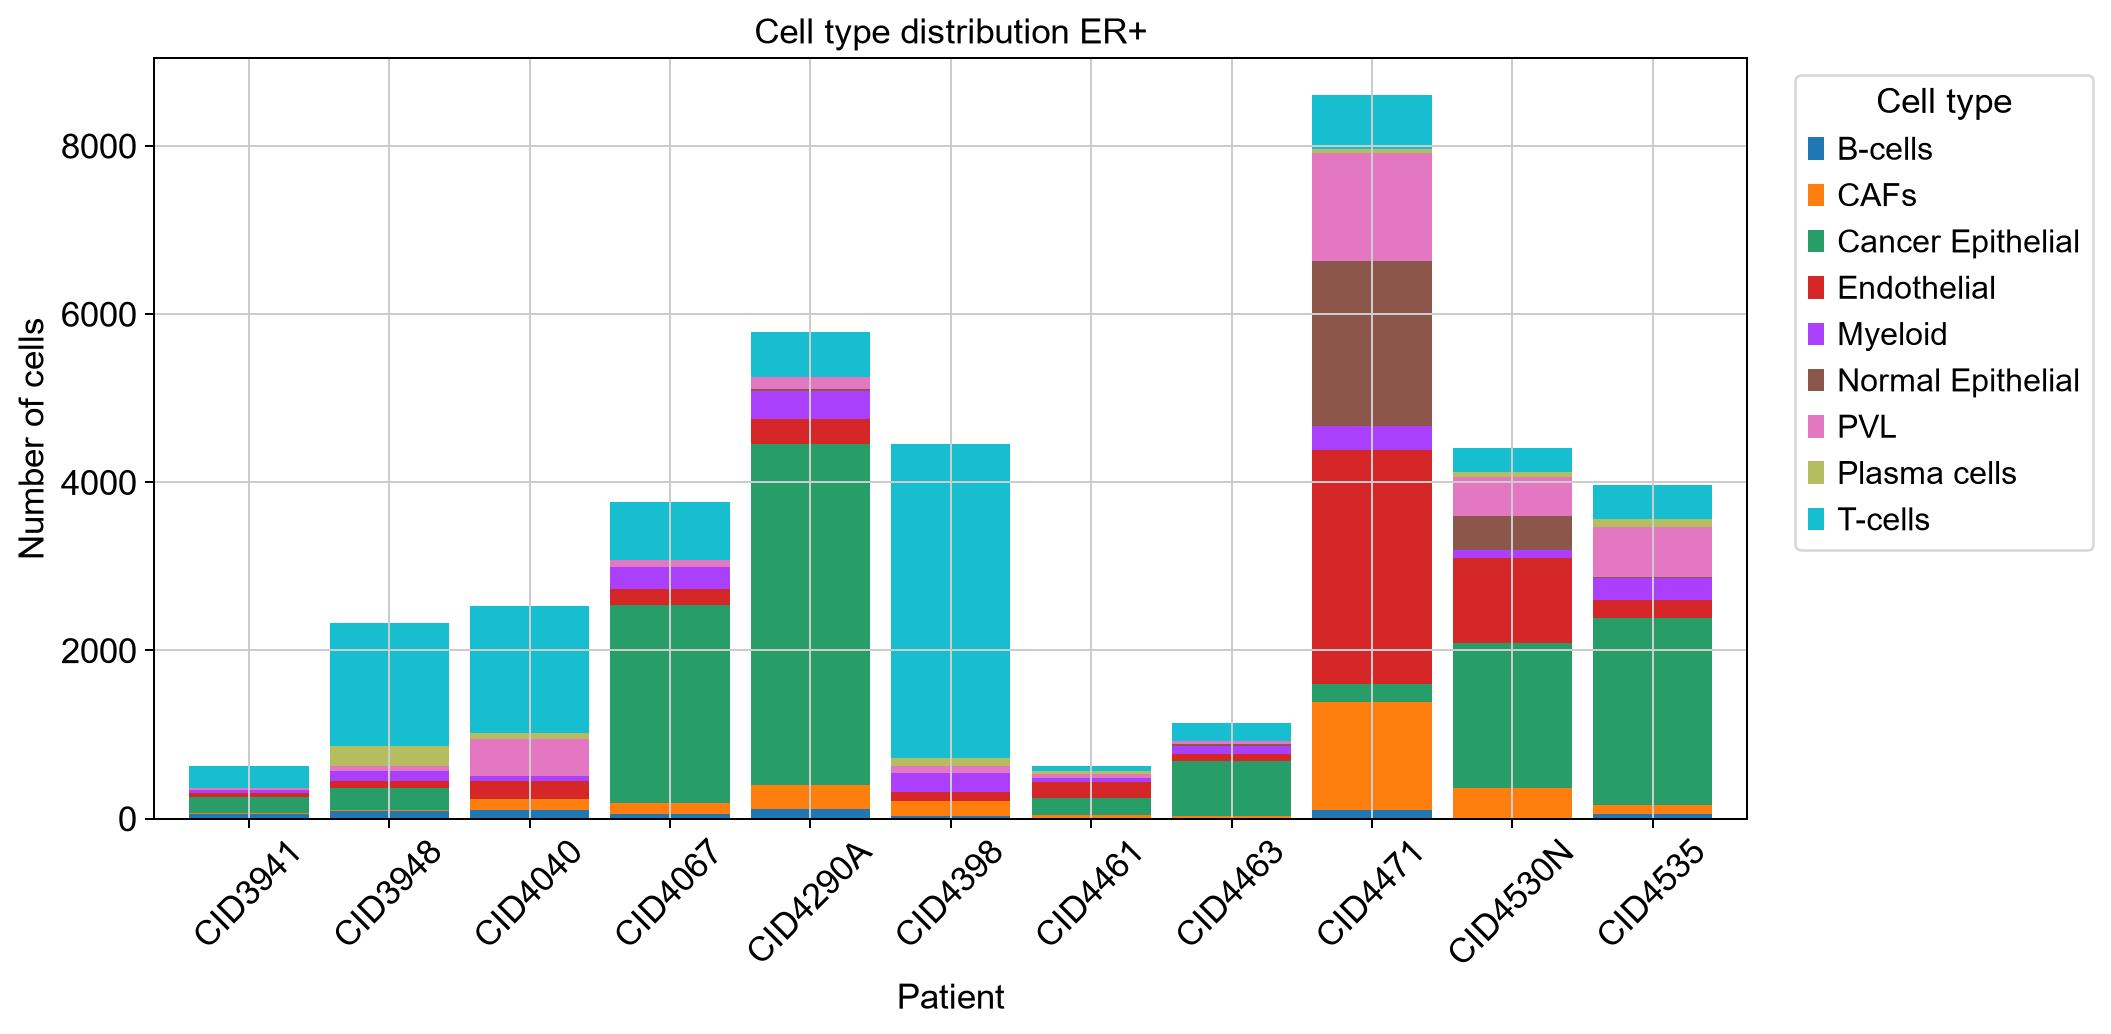

In [72]:
adata_subtype_e = adata[
    adata.obs["subtype"] == "ER+"
].copy()

cell_counts = pd.crosstab(
    adata_subtype_e.obs["patient"],
    adata_subtype_e.obs["celltype"]
)

# Plot
ax = cell_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85
)

ax.set_title("Cell type distribution ER+")
ax.set_xlabel("Patient")
ax.set_ylabel("Number of cells")
ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

CID4067 y CID4290A que podrían servir para nuestro experimento, ya que tienen características similares, vienen del mismo batch, es decir, más evidencias de que pacientes de distintos batches tienen diferencias técnicas.